In [1]:
# ============================== CONFIG ==============================
import os, sys
NOTEBOOK_DIR = os.getcwd()
FIA_DIR = r'C:\Users\DCifelli2\Downloads\WV_CSV'                         # folder with WV_*.csv, or the filtered folder from notebook 00 (WV_*.csv.gz)
GDB = os.path.join(r'.', 'gdb_export')  # Fernow tables (for comparison values)
FERNOW_LATLON = (39.06, -79.68)
HARDWOOD = [(500, 599), (800, 899)]     # oak/hickory, maple/beech/birch forest-type groups
MIN_INVYR = 2004                         # annual inventory only (periodic 1989/2000 lack treatment codes)
FERNOW_SECTION = None                    # None = derive from FIA plots within 15 km of Fernow
EXPORT_TO_GDB = False                    # §6: write latest-visit FIA plots to the ArcGIS Pro default geodatabase
# ====================================================================
sys.path.insert(0, NOTEBOOK_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
from fernow_stats import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
QC = []
def qc(step, df):
    QC.append((step, len(df))); print(f'[QC] {step}: {len(df):,} rows')
def fia(name):
    # path to WV_<name>.csv.gz (filtered by notebook 00) or WV_<name>.csv (raw); None if absent
    for ext in ('.csv.gz', '.csv'):
        p = os.path.join(FIA_DIR, f'WV_{name}{ext}')
        if os.path.exists(p): return p
    return None
for t in ['PLOT', 'COND', 'PLOTGEOM', 'COND_DWM_CALC']:
    assert fia(t), f'missing WV_{t}(.csv/.csv.gz) in FIA_DIR'
print('FIA files found:', {t: (os.path.basename(fia(t)) if fia(t) else None) for t in ['PLOT', 'COND', 'PLOTGEOM', 'COND_DWM_CALC', 'TREE', 'SEEDLING']})

<class 'ModuleNotFoundError'>: No module named 'fernow_stats'

In [2]:
import os
print(os.getcwd())
print(os.path.exists(r'C:\Users\DCifelli2\...\Fernow_Notebooks\fernow_stats.py'))

C:\Users\DCifelli2\OneDrive - mercercounty.org\Documents\ArcGIS\Projects\Fernow-FM-SOM-DC-092026
False


In [1]:
import os, sys
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
FIA_DIR = r'C:\Users\DCifelli2\Downloads\WV_CSV'          # later: the filtered folder from notebook 00
GDB = os.path.join(NOTEBOOK_DIR, 'gdb_export')

In [2]:
import os, sys
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
DATA_ROOT = NOTEBOOK_DIR
GDB = os.path.join(DATA_ROOT, 'gdb_export')

In [3]:
DATA = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks\gdb_export'

In [4]:
DATA = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks\gdb_export'

In [5]:
import os
d = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
print(os.path.exists(os.path.join(d, 'fernow_stats.py')), os.path.exists(os.path.join(d, 'gdb_export', 'trees.csv')))

True False


In [6]:
DATA = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main\gdb_export'

In [7]:
import os, sys
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
DATA_ROOT = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main'
GDB = os.path.join(DATA_ROOT, 'gdb_export')

In [8]:
import os, sys
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
FIA_DIR = r'C:\Users\DCifelli2\Downloads\WV_CSV'
GDB = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main\gdb_export'

In [9]:
import os
print(os.path.exists(r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks\fernow_stats.py'),
      os.path.exists(r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main\gdb_export\trees.csv'))

True True


In [10]:
P = pd.read_csv(fia('PLOT'), low_memory=False,
                usecols=['CN', 'INVYR', 'COUNTYCD', 'PLOT', 'PLOT_STATUS_CD', 'MEASYEAR', 'LAT', 'LON', 'ELEV', 'PREV_PLT_CN', 'REMPER'])
C = pd.read_csv(fia('COND'), low_memory=False,
                usecols=['CN', 'PLT_CN', 'INVYR', 'CONDID', 'COND_STATUS_CD', 'CONDPROP_UNADJ', 'FORTYPCD', 'STDAGE', 'STDORGCD',
                         'SITECLCD', 'SLOPE', 'ASPECT', 'OWNGRPCD', 'BALIVE', 'DSTRBCD1', 'DSTRBCD2', 'DSTRBCD3',
                         'TRTCD1', 'TRTCD2', 'TRTCD3', 'TRTYR1', 'TRTYR2', 'TRTYR3',
                         'CARBON_DOWN_DEAD', 'CARBON_LITTER', 'CARBON_SOIL_ORG', 'CARBON_UNDERSTORY_AG', 'CARBON_UNDERSTORY_BG'])
G = pd.read_csv(fia('PLOTGEOM'), low_memory=False, usecols=['CN', 'ECOSUBCD'])
G['ECOSUBCD'] = G.ECOSUBCD.astype(str).str.strip(); G['SECTION'] = G.ECOSUBCD.str[:5]
qc('COND all', C)

c = C[C.INVYR >= MIN_INVYR]; qc(f'annual inventory (INVYR >= {MIN_INVYR})', c)
c = c[c.COND_STATUS_CD == 1]; qc('accessible forest land', c)
hw = np.zeros(len(c), bool)
for lo, hi in HARDWOOD: hw |= c.FORTYPCD.between(lo, hi).values
c = c[hw]; qc('hardwood forest types (500s, 800s)', c)
c = c[c.STDORGCD.fillna(0) == 0]; qc('natural origin (not planted)', c)

def prep(df):
    df = df.merge(P.rename(columns={'CN': 'PLT_CN', 'INVYR': 'INVYR_P'}), on='PLT_CN')
    df = df.merge(G.rename(columns={'CN': 'PLT_CN'}), on='PLT_CN', how='left')
    df['pid'] = df.COUNTYCD.astype(str) + '_' + df.PLOT.astype(str)
    df['elev_m'] = df.ELEV * 0.3048
    df['slope_pct'] = df.SLOPE
    df['northness'] = np.where(df.SLOPE > 0, np.cos(np.deg2rad(df.ASPECT)), 0.0)
    df['cut'] = (df[['TRTCD1', 'TRTCD2', 'TRTCD3']] == 10).any(axis=1)
    df['disturbed'] = (df[['DSTRBCD1', 'DSTRBCD2', 'DSTRBCD3']].fillna(0) > 0).any(axis=1)
    trt_yr = df[['TRTYR1', 'TRTYR2', 'TRTYR3']].where(df[['TRTCD1', 'TRTCD2', 'TRTCD3']].values == 10)
    df['yrs_since_cut'] = np.where(df.cut, df.MEASYEAR - trt_yr.max(axis=1), np.nan)
    df['ftgroup'] = np.where(df.FORTYPCD < 600, 'oak/hickory', 'maple/beech/birch')
    return df

c_multi = prep(c.copy())   # all hardwood conditions incl. partial ones — used for per-acre DWM carbon (§4)
print(f'   BALIVE max before single-condition filter: {c.BALIVE.max():.0f} ft2/ac (artifact of tiny partial conditions)')
c = c[c.CONDPROP_UNADJ == 1]; qc('single-condition plots (CONDPROP_UNADJ = 1) — for BALIVE analyses', c)
print(f'   BALIVE max after: {c.BALIVE.max():.0f} ft2/ac')
c = prep(c)

c_multi['in_section'] = False
if FERNOW_SECTION is None:
    d_km = np.hypot((c.LAT - FERNOW_LATLON[0]) * 111.0, (c.LON - FERNOW_LATLON[1]) * 86.0)
    FERNOW_SECTION = c.loc[d_km < 15, 'SECTION'].mode().iat[0]
    print(f'Fernow ecological section (mode of FIA plots within 15 km): {FERNOW_SECTION}; subsections nearby:',
          c.loc[d_km < 15, 'ECOSUBCD'].value_counts().head(3).to_dict())
c['in_section'] = c.SECTION == FERNOW_SECTION; c_multi['in_section'] = c_multi.SECTION == FERNOW_SECTION

latest = c.sort_values('INVYR').groupby('pid').tail(1).copy(); qc('latest visit per plot (cross-sectional sample)', latest)
print(f"Latest-visit: {latest.cut.sum()} with cutting recorded; {latest.in_section.sum()} in section {FERNOW_SECTION}")

<class 'NameError'>: name 'pd' is not defined

In [2]:
# ============================== CONFIG ==============================
import os, glob, time
IN_DIR  = r'C:\Users\DCifelli2\Downloads\WV_CSV'            # full FIA download
OUT_DIR = r'C:\Users\DCifelli2\Downloads\WV_CSV_filtered'   # compressed, filtered output (copy into the repo)

MIN_INVYR = 2000                 # keep 2000 so 2004+ annual plots can link to their previous visit
SCOPE = 'WV'                     # 'WV' (default, all plots) | 'SECTION' (ECOSUBCD section, e.g. M221B) | 'RADIUS'
SECTION = 'M221B'                # used when SCOPE == 'SECTION'
FERNOW_LATLON, RADIUS_KM = (39.06, -79.68), 60   # used when SCOPE == 'RADIUS'

SKIP = ['TREE_GRM_ESTN', 'OZONE']      # substrings of tables not needed (GRM_ESTN is enormous)
COPY_WHOLE_MAX_MB = 50           # tables with no plot/tree key are copied whole only if smaller than this
CHUNK = 500_000

# Column subsets for the big tables (others keep every column). Missing columns are ignored, so FIADB version changes are safe.
COLS = {
    'TREE': ['CN', 'PLT_CN', 'PREV_TRE_CN', 'INVYR', 'CONDID', 'SUBP', 'TREE', 'STATUSCD', 'SPCD', 'SPGRPCD', 'DIA', 'HT',
             'ACTUALHT', 'CR', 'CCLCD', 'TREECLCD', 'AGENTCD', 'STANDING_DEAD_CD', 'DECAYCD', 'MORTYR', 'PREVDIA',
             'RECONCILECD', 'TPA_UNADJ', 'DRYBIO_AG', 'DRYBIO_BG', 'CARBON_AG', 'CARBON_BG'],
    'TREE_GRM_COMPONENT': ['TRE_CN', 'PREV_TRE_CN', 'PLT_CN', 'STATECD', 'DIA_BEGIN', 'DIA_MIDPT', 'DIA_END',
                           'SUBP_COMPONENT_AL_FOREST', 'SUBP_SUBPTYP_GRM_AL_FOREST', 'SUBP_TPAGROW_UNADJ_AL_FOREST',
                           'SUBP_TPAREMV_UNADJ_AL_FOREST', 'SUBP_TPAMORT_UNADJ_AL_FOREST'],
    'TREE_GRM_BEGIN': ['TRE_CN', 'PLT_CN', 'DIA', 'CARBON_AG', 'CARBON_BG', 'DRYBIO_AG', 'DRYBIO_BG'],
    'TREE_GRM_MIDPT': ['TRE_CN', 'PLT_CN', 'DIA', 'STATUSCD', 'CARBON_AG', 'CARBON_BG', 'DRYBIO_AG', 'DRYBIO_BG'],
}
# ====================================================================
import numpy as np, pandas as pd
LBAC_TO_MGHA = 0.00112085
os.makedirs(OUT_DIR, exist_ok=True)
files = sorted(glob.glob(os.path.join(IN_DIR, '*.csv')))
inv = pd.DataFrame({'file': [os.path.basename(f) for f in files],
                    'MB': [os.path.getsize(f) / 1e6 for f in files]}).sort_values('MB', ascending=False)
print(f'{len(files)} CSVs, {inv.MB.sum():,.0f} MB total'); inv.head(25).round(1)

68 CSVs, 973 MB total


,file,MB
59,WV_TREE_GRM_ESTN.csv,272.1
56,WV_TREE.csv,203.3
58,WV_TREE_GRM_COMPONENT.csv,79.8
60,WV_TREE_GRM_MIDPT.csv,79.6
57,WV_TREE_GRM_BEGIN.csv,77.9
15,WV_FVS_TREEINIT_PLOT.csv,58.9
14,WV_FVS_TREEINIT_COND.csv,57.6
32,WV_PLOTSNAP.csv,28.8
39,WV_POP_PLOT_STRATUM_ASSGN.csv,17.3
11,WV_FVS_PLOTINIT_PLOT.csv,16.2


In [12]:
def table_name(path):                       # 'WV_TREE.csv' -> 'TREE'
    return os.path.basename(path)[:-4].split('_', 1)[1]
path_of = {table_name(f): f for f in files}
assert 'PLOT' in path_of, 'WV_PLOT.csv not found in IN_DIR'

P = pd.read_csv(path_of['PLOT'], low_memory=False, dtype={'CN': str, 'PREV_PLT_CN': str})
n0 = len(P)
P = P[P.INVYR >= MIN_INVYR]
if SCOPE == 'SECTION':
    G = pd.read_csv(path_of['PLOTGEOM'], usecols=['CN', 'ECOSUBCD'], dtype={'CN': str})
    keep = G.loc[G.ECOSUBCD.astype(str).str.strip().str.startswith(SECTION), 'CN']
    P = P[P.CN.isin(keep)]
elif SCOPE == 'RADIUS':
    d = np.hypot((P.LAT - FERNOW_LATLON[0]) * 111.0, (P.LON - FERNOW_LATLON[1]) * 111.32 * np.cos(np.deg2rad(FERNOW_LATLON[0])))
    P = P[d <= RADIUS_KM]
PLOTS = set(P.CN)
print(f'PLOT: {n0:,} -> {len(P):,} plot visits kept (SCOPE={SCOPE}, INVYR >= {MIN_INVYR})')

PLOT: 16,447 -> 13,106 plot visits kept (SCOPE=WV, INVYR >= 2000)


In [13]:
manifest, TREES = [], set()

def filter_table(name, path):
    t0 = time.time()
    if any(s in name for s in SKIP):
        manifest.append(dict(table=name, action='skipped (SKIP list)', rows_in=np.nan, rows_out=0,
                             MB_in=os.path.getsize(path) / 1e6, MB_out=0)); return
    header = pd.read_csv(path, nrows=0).columns.tolist()
    usecols = [c for c in COLS[name] if c in header] if name in COLS else header
    key = 'CN' if name in ('PLOT', 'PLOTGEOM', 'PLOTSNAP') else ('PLT_CN' if 'PLT_CN' in header else ('TRE_CN' if 'TRE_CN' in header else None))
    out = os.path.join(OUT_DIR, f'WV_{name}.csv.gz')
    mb_in = os.path.getsize(path) / 1e6
    if key is None:
        if mb_in <= COPY_WHOLE_MAX_MB:
            df = pd.read_csv(path, low_memory=False); df.to_csv(out, index=False, compression='gzip')
            manifest.append(dict(table=name, action='copied whole (no plot key)', rows_in=len(df), rows_out=len(df),
                                 MB_in=mb_in, MB_out=os.path.getsize(out) / 1e6))
        else:
            manifest.append(dict(table=name, action='skipped (no key, too large)', rows_in=np.nan, rows_out=0, MB_in=mb_in, MB_out=0))
        return
    keyset = PLOTS if key in ('CN', 'PLT_CN') else TREES
    n_in = n_out = 0; first = True
    dtypes = {c: str for c in usecols if c == 'CN' or c.endswith('_CN')}
    for ch in pd.read_csv(path, usecols=usecols, dtype=dtypes, chunksize=CHUNK, low_memory=False):
        n_in += len(ch)
        ch = ch[ch[key].isin(keyset)]
        if name == 'TREE':
            TREES.update(ch['CN'])
        n_out += len(ch)
        ch.to_csv(out, index=False, compression='gzip', mode='w' if first else 'a', header=first); first = False
    manifest.append(dict(table=name, action=f'filtered on {key}', rows_in=n_in, rows_out=n_out,
                         MB_in=mb_in, MB_out=os.path.getsize(out) / 1e6))
    print(f'{name:28s} {n_in:>11,} -> {n_out:>10,} rows   {mb_in:8.1f} -> {os.path.getsize(out) / 1e6:7.1f} MB   ({time.time() - t0:.0f} s)')

order = ['PLOT', 'TREE'] + [n for n in path_of if n not in ('PLOT', 'TREE')]
for name in order:
    if name in path_of:
        filter_table(name, path_of[name])
M = pd.DataFrame(manifest); M.to_csv(os.path.join(OUT_DIR, 'MANIFEST.csv'), index=False)
print(f"\nTotal: {M.MB_in.sum():,.0f} MB in -> {M.MB_out.sum():,.1f} MB out")
big = M[M.MB_out > 95]
if len(big):
    print('WARNING — over GitHub\'s 100 MB per-file limit (raise MIN_INVYR, narrow SCOPE, or keep local):', big.table.tolist())
M.round(1)

PLOT                              16,447 ->     13,106 rows        3.6 ->     0.4 MB   (1 s)
TREE                             406,329 ->    330,078 rows      203.3 ->    11.7 MB   (12 s)
COND                              21,227 ->     17,886 rows        7.3 ->     1.0 MB   (2 s)
COND_DWM_CALC                      4,129 ->      4,129 rows        3.6 ->     0.6 MB   (0 s)
DWM_COARSE_WOODY_DEBRIS            3,915 ->      3,915 rows        1.4 ->     0.2 MB   (0 s)
DWM_DUFF_LITTER_FUEL               8,116 ->      8,116 rows        0.9 ->     0.1 MB   (0 s)
DWM_FINE_WOODY_DEBRIS              3,124 ->      3,124 rows        0.6 ->     0.0 MB   (0 s)
DWM_MICROPLOT_FUEL                   693 ->        693 rows        0.1 ->     0.0 MB   (0 s)
DWM_RESIDUAL_PILE                     10 ->         10 rows        0.0 ->     0.0 MB   (0 s)
DWM_TRANSECT_SEGMENT               8,358 ->      8,358 rows        1.1 ->     0.1 MB   (0 s)
DWM_VISIT                            908 ->        908 rows        0.

,table,action,rows_in,rows_out,MB_in,MB_out
0,PLOT,filtered on CN,16447.0,13106,3.6,0.4
1,TREE,filtered on PLT_CN,406329.0,330078,203.3,11.7
2,COND,filtered on PLT_CN,21227.0,17886,7.3,1.0
3,COND_DWM_CALC,filtered on PLT_CN,4129.0,4129,3.6,0.6
4,COUNTY,copied whole (no plot key),55.0,55,0.0,0.0
...,...,...,...,...,...,...
63,VEG_PLOT_SPECIES,filtered on PLT_CN,9353.0,9353,1.0,0.1
64,VEG_QUADRAT,filtered on PLT_CN,1176.0,1176,0.1,0.0
65,VEG_SUBPLOT,filtered on PLT_CN,424.0,424,0.1,0.0
66,VEG_SUBPLOT_SPP,filtered on PLT_CN,18164.0,18164,2.9,0.3


In [14]:
cond_path = os.path.join(OUT_DIR, 'WV_COND.csv.gz')
C = pd.read_csv(cond_path, dtype={'PLT_CN': str},
                usecols=lambda c: c in ['PLT_CN', 'CONDID', 'CONDPROP_UNADJ', 'SUBPPROP_UNADJ', 'MICRPROP_UNADJ', 'COND_STATUS_CD'])
parts = []
VALS = ['live_AGC', 'live_BGC', 'live_BA', 'live_TPA', 'large_AGC', 'snag_AGC']
for ch in pd.read_csv(os.path.join(OUT_DIR, 'WV_TREE.csv.gz'), dtype={'CN': str, 'PLT_CN': str}, chunksize=CHUNK):
    ch = ch[ch.TPA_UNADJ.notna() & ch.DIA.notna()].copy()
    live = (ch.STATUSCD == 1).values
    snag = ((ch.STATUSCD == 2) & (ch.STANDING_DEAD_CD == 1)).values if 'STANDING_DEAD_CD' in ch else (ch.STATUSCD == 2).values
    tpa = ch.TPA_UNADJ.values
    cag = ch.CARBON_AG.fillna(0).values * tpa; cbg = ch.CARBON_BG.fillna(0).values * tpa
    ch['live_AGC'] = np.where(live, cag, 0.0)
    ch['live_BGC'] = np.where(live, cbg, 0.0)
    ch['live_BA'] = np.where(live, 0.005454154 * ch.DIA.values ** 2 * tpa, 0.0)
    ch['live_TPA'] = np.where(live, tpa, 0.0)
    ch['large_AGC'] = np.where(live & (ch.DIA.values >= 19.7), cag, 0.0)
    ch['snag_AGC'] = np.where(snag, cag, 0.0)
    ch['grp'] = np.where(ch.DIA.values < 5.0, 'sap', 'tree')
    parts.append(ch.groupby(['PLT_CN', 'CONDID', 'grp'])[VALS].sum().reset_index())
T = pd.concat(parts).groupby(['PLT_CN', 'CONDID', 'grp']).sum().reset_index()
T = T.merge(C, on=['PLT_CN', 'CONDID'], how='left')
T['prop'] = np.where(T.grp == 'sap', T.MICRPROP_UNADJ, T.SUBPPROP_UNADJ)
T = T[T.prop > 0]
T[VALS] = T[VALS].div(T.prop, axis=0)
W = T.pivot_table(index=['PLT_CN', 'CONDID'], columns='grp',
                  values=['live_AGC', 'live_BGC', 'live_BA', 'live_TPA', 'large_AGC', 'snag_AGC'], fill_value=0)
W.columns = [f'{a}_{b}' for a, b in W.columns]; W = W.reset_index()
live = pd.DataFrame({'PLT_CN': W.PLT_CN, 'CONDID': W.CONDID,
    'live_AGC_MgHa': (W.get('live_AGC_tree', 0) + W.get('live_AGC_sap', 0)) * LBAC_TO_MGHA,
    'live_BGC_MgHa': (W.get('live_BGC_tree', 0) + W.get('live_BGC_sap', 0)) * LBAC_TO_MGHA,
    'large_AGC_MgHa': W.get('large_AGC_tree', 0) * LBAC_TO_MGHA,
    'snag_AGC_MgHa': (W.get('snag_AGC_tree', 0) + W.get('snag_AGC_sap', 0)) * LBAC_TO_MGHA,
    'live_BA_ft2ac': W.get('live_BA_tree', 0) + W.get('live_BA_sap', 0),
    'trees_per_ac_ge5in': W.get('live_TPA_tree', 0),
    'saplings_per_ac': W.get('live_TPA_sap', 0)})
live['large_tree_share'] = np.where(live.live_AGC_MgHa > 0, live.large_AGC_MgHa / live.live_AGC_MgHa, np.nan)
live.to_csv(os.path.join(OUT_DIR, 'fia_cond_live.csv.gz'), index=False, compression='gzip')
print(f'fia_cond_live: {len(live):,} plot-conditions'); live.describe().round(2)

fia_cond_live: 11,057 plot-conditions


,CONDID,live_AGC_MgHa,live_BGC_MgHa,large_AGC_MgHa,snag_AGC_MgHa,live_BA_ft2ac,trees_per_ac_ge5in,saplings_per_ac,large_tree_share
count,11057.00,11057.00,11057.00,11057.00,11057.00,11057.00,11057.00,11057.00,11045.00
mean,1.24,81.70,14.48,19.38,2.56,115.86,158.02,369.04,0.16
std,0.51,62.62,10.89,37.80,6.58,97.99,390.03,402.40,0.22
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,47.51,8.74,0.00,0.00,80.69,108.36,99.95,0.00
50%,1.00,74.05,13.49,0.00,0.80,110.60,145.98,299.84,0.00
75%,1.00,104.62,18.52,26.17,2.92,142.38,192.58,524.72,0.30
max,5.00,2188.58,437.07,771.84,440.68,7583.56,40133.33,6178.02,1.00


In [15]:
def spgroup(spcd):
    s = np.asarray(spcd)
    return np.select([(s >= 800) & (s <= 899), s == 316, s == 318, s == 315, s == 531, np.isin(s, [371, 372, 373, 375, 379]),
                      s == 762, s == 621, (s >= 400) & (s <= 499)],
                     ['oak', 'red_maple', 'sugar_maple', 'striped_maple', 'beech', 'birch', 'black_cherry', 'yellow_poplar', 'hickory'],
                     'other')
sp = os.path.join(OUT_DIR, 'WV_SEEDLING.csv.gz')
if os.path.exists(sp):
    S = pd.read_csv(sp, dtype={'PLT_CN': str}, low_memory=False)
    cnt = 'TREECOUNT_CALC' if 'TREECOUNT_CALC' in S else 'TREECOUNT'
    S['spa'] = S[cnt].fillna(0) * S.TPA_UNADJ.fillna(0)
    S['group'] = spgroup(S.SPCD)
    sd = S.pivot_table(index=['PLT_CN', 'CONDID'], columns='group', values='spa', aggfunc='sum', fill_value=0)
    sd.columns = [f'seedl_{c}' for c in sd.columns]; sd = sd.reset_index()
    sd = sd.merge(C[['PLT_CN', 'CONDID', 'MICRPROP_UNADJ']], on=['PLT_CN', 'CONDID'], how='left')
    sd = sd[sd.MICRPROP_UNADJ > 0]
    sc = [c for c in sd.columns if c.startswith('seedl_')]
    sd[sc] = sd[sc].div(sd.MICRPROP_UNADJ, axis=0)
    sd['seedl_total'] = sd[sc].sum(axis=1)
    sd.drop(columns='MICRPROP_UNADJ').to_csv(os.path.join(OUT_DIR, 'fia_cond_seedlings.csv.gz'), index=False, compression='gzip')
    print(f'fia_cond_seedlings: {len(sd):,} plot-conditions with seedlings recorded (conditions with none are absent = 0)')
    print(sd[sc + ['seedl_total']].median().round(0))
else:
    print('WV_SEEDLING not found — seedling summary skipped.')

fia_cond_seedlings: 9,476 plot-conditions with seedlings recorded (conditions with none are absent = 0)
seedl_beech               0.0
seedl_birch               0.0
seedl_black_cherry        0.0
seedl_hickory             0.0
seedl_oak                 0.0
seedl_other             373.0
seedl_red_maple           0.0
seedl_striped_maple       0.0
seedl_sugar_maple         0.0
seedl_yellow_poplar       0.0
seedl_total            2249.0
dtype: float64


In [16]:
import os
DATA = r'gdb_export'          # <-- EDIT ME if the notebook is not sitting next to the gdb_export folder

# If True, the ecosystem-C figure scales POM/MAOM so their sum equals bulk soil C (mass-balance-consistent stack).
# If False, POM/MAOM are plotted exactly as measured (fraction recovery 86-113% of bulk; both are defensible,
# the choice just has to be stated in the caption).
SCALE_FRACTIONS_TO_BULK = True
# ==========================================================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 140); pd.set_option('display.max_columns', 40)

ORDER  = ['WS4', 'WS2', 'WS5']                       # REF, DLC, STS — keep this order everywhere
LABELS = {'WS4': 'REF', 'WS2': 'DLC', 'WS5': 'STS'}
COLORS = {'WS4': '#4C6444', 'WS2': '#B0733A', 'WS5': '#3A6EA5'}

for f in ['trees.csv', 'soil_samples.csv', 'soil_fractions.csv']:
    assert os.path.exists(os.path.join(DATA, f)), f'Cannot find {f} in DATA — fix the DATA path above.'
print('scipy', __import__('scipy').__version__, '| pandas', pd.__version__, '| data folder OK')


scipy 1.9.3 | pandas 2.0.2 | data folder OK


In [17]:
# ---------- Shared statistical helpers (no packages beyond scipy needed) ----------

def welch_anova(groups):
    """Welch's heteroscedasticity-robust one-way ANOVA (matches R oneway.test var.equal=FALSE)."""
    k = len(groups); n = np.array([len(g) for g in groups], float)
    m = np.array([g.mean() for g in groups]); v = np.array([g.var(ddof=1) for g in groups])
    w = n / v
    grand = np.sum(w * m) / np.sum(w)
    num = np.sum(w * (m - grand) ** 2) / (k - 1)
    tmp = np.sum((1 - w / np.sum(w)) ** 2 / (n - 1))
    F = num / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    df2 = (k ** 2 - 1) / (3 * tmp)
    return F, 1 - stats.f.cdf(F, k - 1, df2)

def dunnett_vs_control(groups):
    """Dunnett's test vs. groups[0]. Uses scipy.stats.dunnett when available (SciPy >= 1.11);
    otherwise falls back to Welch t-tests vs. control with Holm correction (slightly conservative)
    and says so, so the output is never silently different between environments."""
    try:
        from scipy.stats import dunnett as _dunnett
        res = _dunnett(*groups[1:], control=groups[0])
        return list(res.pvalue), 'Dunnett (scipy)'
    except ImportError:
        p = [stats.ttest_ind(g, groups[0], equal_var=False).pvalue for g in groups[1:]]
        order = np.argsort(p); m = len(p); adj = np.empty(m)
        running = 0.0
        for rank, idx in enumerate(order):
            running = max(running, (m - rank) * p[idx]); adj[idx] = min(running, 1.0)
        return list(adj), 'Welch t + Holm (scipy<1.11 fallback)'

def bh_fdr(pvals):
    """Benjamini-Hochberg adjusted p-values (manual — statsmodels not in arcgispro-py3)."""
    p = np.asarray(pvals, float); m = len(p)
    order = np.argsort(p); ranked = p[order] * m / (np.arange(m) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(m); out[order] = np.minimum(ranked, 1.0)
    return out

def anova_power(groups, alpha=0.05):
    """Post-hoc power for the one-way ANOVA via the noncentral F distribution."""
    m = [g.mean() for g in groups]
    pooled = np.mean([g.var(ddof=1) for g in groups])
    f_eff = np.sqrt(np.mean([(x - np.mean(m)) ** 2 for x in m]) / pooled)   # Cohen's f
    N = sum(len(g) for g in groups); k = len(groups)
    nc = f_eff ** 2 * N
    fcrit = stats.f.ppf(1 - alpha, k - 1, N - k)
    return f_eff, stats.ncf.sf(fcrit, k - 1, N - k, nc)

def battery(groups):
    """Full assumption-checked battery. groups[0] must be REF."""
    groups = [np.asarray(g, float) for g in groups]
    groups = [g[~np.isnan(g)] for g in groups]
    F, p = stats.f_oneway(*groups)
    _, lev_p = stats.levene(*groups)
    _, sh_p = stats.shapiro(np.concatenate([g - g.mean() for g in groups]))
    H, pk = stats.kruskal(*groups)
    Fw, pw = welch_anova(groups)
    dun_p, dun_method = dunnett_vs_control(groups)
    f_eff, power = anova_power(groups)
    return dict(n=[len(g) for g in groups], means=[g.mean() for g in groups],
                sds=[g.std(ddof=1) for g in groups], F=F, p=p, lev_p=lev_p, sh_p=sh_p,
                Fw=Fw, pw=pw, H=H, pk=pk, dunnett_p=dun_p, dunnett_method=dun_method,
                f_eff=f_eff, power=power)

print('Helpers loaded.')


Helpers loaded.


In [18]:
trees = pd.read_csv(os.path.join(DATA, 'trees.csv'))
trees = trees[trees.dbh_cm.notna()].copy()
PLOT_AREA_M2 = 404.70782
trees['agbC_kg'] = trees['agb_kg_jenkins'] * 0.48

agb_plot = trees.groupby(['watershed', 'plot_id'])['agbC_kg'].sum().reset_index()
agb_plot['MgC_ha'] = agb_plot['agbC_kg'] / 1000 / (PLOT_AREA_M2 / 10000)

summary = agb_plot.groupby('watershed')['MgC_ha'].agg(['count', 'mean', 'std']).reindex(ORDER)
summary.index = [LABELS[w] for w in summary.index]
print('AGB-C by watershed (Mg C/ha), plot level:'); print(summary.round(1))

groups = [agb_plot[agb_plot.watershed == w]['MgC_ha'].values for w in ORDER]
r = battery(groups)
print(f"\nANOVA F={r['F']:.2f} p={r['p']:.4f} | Levene p={r['lev_p']:.4f} (fails -> lead with Welch/KW) | Shapiro p={r['sh_p']:.4f}")
print(f"Welch p={r['pw']:.4f} | Kruskal-Wallis p={r['pk']:.4f}")
print(f"{r['dunnett_method']} vs REF: DLC p={r['dunnett_p'][0]:.4f}, STS p={r['dunnett_p'][1]:.4f}")
print(f"Cohen's f={r['f_eff']:.2f}, power={r['power']:.2f}")


AGB-C by watershed (Mg C/ha), plot level:
     count   mean   std
REF      6  177.4  44.8
DLC      6   89.0  14.8
STS      6   90.6  42.4

ANOVA F=11.46 p=0.0010 | Levene p=0.0385 (fails -> lead with Welch/KW) | Shapiro p=0.8647
Welch p=0.0072 | Kruskal-Wallis p=0.0083
Welch t + Holm (scipy<1.11 fallback) vs REF: DLC p=0.0072, STS p=0.0072
Cohen's f=1.13, power=0.98


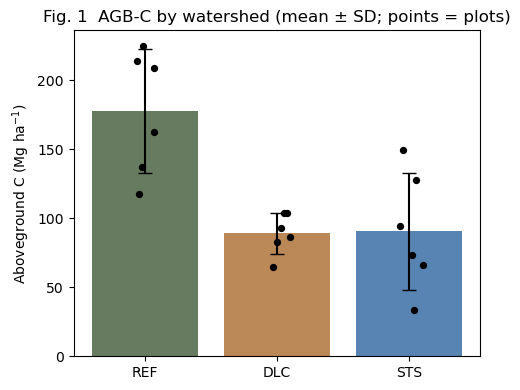

In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
for i, w in enumerate(ORDER):
    vals = agb_plot[agb_plot.watershed == w]['MgC_ha'].values
    ax.bar(i, vals.mean(), yerr=vals.std(ddof=1), capsize=5, color=COLORS[w], alpha=0.85)
    ax.scatter(np.full(len(vals), i) + np.random.uniform(-0.12, 0.12, len(vals)), vals,
               color='k', zorder=3, s=18)
ax.set_xticks(range(3)); ax.set_xticklabels([LABELS[w] for w in ORDER])
ax.set_ylabel('Aboveground C (Mg ha$^{-1}$)')
ax.set_title('Fig. 1  AGB-C by watershed (mean ± SD; points = plots)')
plt.tight_layout(); plt.show()

In [20]:
full_plots = agb_plot[['watershed', 'plot_id']].drop_duplicates()
mid = trees[trees.dbh_cm >= 27.9].groupby(['watershed', 'plot_id']).size().reset_index(name='n')
mid = full_plots.merge(mid, how='left').fillna(0)
g = [mid[mid.watershed == w]['n'].values for w in ORDER]
print(f'Stems >=27.9 cm per plot: ANOVA p={stats.f_oneway(*g)[1]:.3f}  (expected n.s.)')

big = trees[trees.dbh_cm >= 50]
print('\nStems >=50 cm by watershed:'); print(big.groupby('watershed').size().reindex(ORDER).fillna(0).astype(int))
ref_t = trees[trees.watershed == 'WS4']
share = ref_t.loc[ref_t.dbh_cm >= 50, 'agbC_kg'].sum() / ref_t['agbC_kg'].sum() * 100
print(f'\nShare of pooled REF AGB-C in >=50 cm stems: {share:.0f}%')
print('Largest stem (cm):', trees.groupby('watershed')['dbh_cm'].max().reindex(ORDER).round(1).to_dict())

Stems >=27.9 cm per plot: ANOVA p=0.347  (expected n.s.)

Stems >=50 cm by watershed:
watershed
WS4    17
WS2     0
WS5    10
dtype: int32

Share of pooled REF AGB-C in >=50 cm stems: 70%
Largest stem (cm): {'WS4': 92.5, 'WS2': 47.0, 'WS5': 71.4}


In [21]:
soil = pd.read_csv(os.path.join(DATA, 'soil_samples.csv'))
resp = ['soil_C_gm2', 'soil_N_gm2', 'soil_CN', 'fine_root_gm2', 'BD_gcm3']
soil_plot = soil.groupby(['watershed', 'soil_plot', 'depth_code'])[resp].mean().reset_index()

rows = []
for var in resp:
    for depth in ['OH', '0-20', '20-40']:
        if var == 'BD_gcm3' and depth == 'OH':
            continue
        d = soil_plot[soil_plot.depth_code == depth]
        g = [d[d.watershed == w][var].dropna().values for w in ORDER]
        r = battery(g)
        rows.append(dict(variable=var, depth=depth,
                         REF=round(r['means'][0], 2), DLC=round(r['means'][1], 2), STS=round(r['means'][2], 2),
                         ANOVA_p=round(r['p'], 4), Welch_p=round(r['pw'], 4), KW_p=round(r['pk'], 4),
                         Levene_p=round(r['lev_p'], 4), Shapiro_p=round(r['sh_p'], 4),
                         Dunnett_DLC=round(r['dunnett_p'][0], 4), Dunnett_STS=round(r['dunnett_p'][1], 4),
                         f=round(r['f_eff'], 2), power=round(r['power'], 2)))
soil_results = pd.DataFrame(rows)

# FDR across the exploratory battery (manual Benjamini-Hochberg)
soil_results['ANOVA_p_FDR'] = bh_fdr(soil_results['ANOVA_p']).round(4)
soil_results['KW_p_FDR'] = bh_fdr(soil_results['KW_p']).round(4)
soil_results

,variable,depth,REF,DLC,STS,ANOVA_p,Welch_p,KW_p,Levene_p,Shapiro_p,Dunnett_DLC,Dunnett_STS,f,power,ANOVA_p_FDR,KW_p_FDR
0,soil_C_gm2,OH,81.56,32.68,49.34,0.0898,0.1032,0.0214,0.3010,0.0019,0.1080,0.2328,0.56,0.47,0.2710,0.1554
1,soil_C_gm2,0-20,5861.81,5325.73,4195.17,0.2086,0.0436,0.0691,0.3391,0.1103,0.6358,0.0310,0.44,0.31,0.2920,0.1935
2,soil_C_gm2,20-40,2511.83,2711.57,1879.55,0.1776,0.1359,0.2291,0.4996,0.0768,0.7013,0.2580,0.46,0.34,0.2920,0.3564
3,soil_N_gm2,OH,2.79,1.25,1.76,0.0518,0.0432,0.0222,0.3801,0.0024,0.0425,0.1767,0.64,0.58,0.2710,0.1554
4,soil_N_gm2,0-20,371.53,293.34,260.22,0.1407,0.1180,0.1345,0.3905,0.5892,0.2484,0.0930,0.50,0.38,0.2870,0.2616
5,soil_N_gm2,20-40,186.55,187.51,172.33,0.8096,0.7510,0.9107,0.4970,0.0304,1.0000,1.0000,0.15,0.08,0.8719,0.9808
6,soil_CN,OH,28.99,25.48,28.58,0.4448,0.4041,0.4758,0.5216,0.5444,0.5414,0.9003,0.31,0.17,0.5661,0.5551
7,soil_CN,0-20,16.04,17.49,16.43,0.6430,0.5553,0.4758,0.5161,0.1957,0.6024,0.8328,0.22,0.11,0.7502,0.5551
8,soil_CN,20-40,12.99,13.98,10.72,0.0600,0.1695,0.0947,0.2037,0.9996,0.4020,0.2008,0.62,0.55,0.2710,0.2210
9,fine_root_gm2,OH,4.66,8.97,4.20,0.1435,0.0736,0.0691,0.7191,0.0062,0.3361,0.8738,0.50,0.38,0.2870,0.1935


In [22]:
# Total mineral-soil C stock, 0-40 cm (Mg/ha) — the belowground headline stock number
wide = soil_plot.pivot_table(index=['watershed', 'soil_plot'], columns='depth_code',
                             values='soil_C_gm2').reset_index()
wide['SoilC_0_40'] = (wide['0-20'] + wide['20-40']) / 100
g = [wide[wide.watershed == w]['SoilC_0_40'].values for w in ORDER]
r = battery(g)
print('Soil C 0-40 cm (Mg/ha):', {LABELS[w]: round(m, 1) for w, m in zip(ORDER, r['means'])})
print(f"ANOVA p={r['p']:.3f} | Welch p={r['pw']:.3f} | KW p={r['pk']:.3f} | power={r['power']:.2f} -> 'not detected'")

Soil C 0-40 cm (Mg/ha): {'REF': 83.7, 'DLC': 80.4, 'STS': 60.7}
ANOVA p=0.105 | Welch p=0.060 | KW p=0.114 | power=0.44 -> 'not detected'


In [23]:
frac = pd.read_csv(os.path.join(DATA, 'soil_fractions.csv'))
sub40 = frac[frac.depth_code == '20-40'].copy()
print(sub40[['watershed', 'soil_plot', 'LF_g', 'LF_C_gm2']].sort_values(['watershed', 'soil_plot']).to_string(index=False))
print('\nLeft-censored LF %C non-detects:', int(sub40['LF_C_gm2'].isna().sum()), '(all WS5)')


watershed  soil_plot   LF_g    LF_C_gm2
      WS2          7 0.0930  954.911983
      WS2          8 0.1274 1628.520484
      WS2          9 0.1743 1306.047920
      WS2         10 0.0434  645.617923
      WS2         11 0.0641  917.210033
      WS2         12 0.0429  605.863059
      WS4         13 0.0367  436.726013
      WS4         14 0.0442  602.875285
      WS4         15 0.0370  308.729519
      WS4         16 0.0456  532.095083
      WS4         17 0.0422  409.419850
      WS4         18 0.0241  424.781207
      WS5         19 0.0190         NaN
      WS5         20 0.0236         NaN
      WS5         21 0.0335  506.643344
      WS5         22 0.0682  811.488940
      WS5         23 0.0253         NaN
      WS5         24 0.0388  706.756760

Left-censored LF %C non-detects: 3 (all WS5)


In [24]:
ref = sub40.loc[sub40.watershed == 'WS4', 'LF_C_gm2'].values
dlc = sub40.loc[sub40.watershed == 'WS2', 'LF_C_gm2'].values
sts = sub40.loc[sub40.watershed == 'WS5', 'LF_C_gm2'].values
dl_floor = frac['LF_C_gm2'].dropna().min()     # smallest observed value = detection-limit proxy

sts_cc = sts[~np.isnan(sts)]
F, p = stats.f_oneway(ref, dlc, sts_cc)
t, pt = stats.ttest_ind(dlc, ref, equal_var=False)
print('PRIMARY — subsoil (20-40 cm) light-fraction CARBON:')
print(f'  Means (gC/m2): REF={ref.mean():.0f}  DLC={dlc.mean():.0f}  STS(detected n=3)={sts_cc.mean():.0f}')
print(f'  DLC/REF enrichment: {dlc.mean()/ref.mean():.2f}x')
print(f'  Focal contrast DLC vs REF (Welch t): p={pt:.4f}')
print(f'  3-group ANOVA (complete-case): p={p:.4f}')

print('\nSENSITIVITY — 3 STS non-detects substituted (STS back to n=6):')
for label, val in [('zero', 0.0), ('half detection limit', dl_floor / 2), ('full detection limit', dl_floor)]:
    sts_f = np.where(np.isnan(sts), val, sts)
    print(f'  {label:22s} STS mean={sts_f.mean():7.1f}   ANOVA p={stats.f_oneway(ref, dlc, sts_f)[1]:.4f}')

PRIMARY — subsoil (20-40 cm) light-fraction CARBON:
  Means (gC/m2): REF=452  DLC=1010  STS(detected n=3)=675
  DLC/REF enrichment: 2.23x
  Focal contrast DLC vs REF (Welch t): p=0.0168
  3-group ANOVA (complete-case): p=0.0127

SENSITIVITY — 3 STS non-detects substituted (STS back to n=6):
  zero                   STS mean=  337.5   ANOVA p=0.0057
  half detection limit   STS mean=  414.7   ANOVA p=0.0048
  full detection limit   STS mean=  491.8   ANOVA p=0.0042


In [25]:
# Supplementary: dry-mass basis (complete data, no censoring) — same story, kept for SI
sub40['LF_massfrac'] = sub40['LF_g'] / sub40['frac_soil_wt_g']
gm = [sub40.loc[sub40.watershed == w, 'LF_massfrac'].values for w in ORDER]
print(f'SI check, LF dry-mass fraction 20-40cm: DLC/REF = {gm[1].mean()/gm[0].mean():.2f}x, '
      f'ANOVA p={stats.f_oneway(*gm)[1]:.4f}, KW p={stats.kruskal(*gm)[1]:.4f}')


SI check, LF dry-mass fraction 20-40cm: DLC/REF = 2.30x, ANOVA p=0.0169, KW p=0.0195


In [26]:
# Full fraction battery, both depths (POM = LF + hPOM computed with half-DL fill for the 3 censored LF values,
# flagged in output; MAOC:totalPOC carried through but pre-flagged as fragile from prior rounds)
frac['LF_C_filled'] = frac['LF_C_gm2'].fillna(dl_floor / 2)
frac['POM_C_gm2'] = frac['LF_C_filled'] + frac['hPOM_C_gm2']

out = []
for var in ['LF_C_gm2', 'hPOM_C_gm2', 'POM_C_gm2', 'MAOM_C_gm2', 'MAOC_tot_POC']:
    for depth in ['0-20', '20-40']:
        d = frac[frac.depth_code == depth]
        g = [d.loc[d.watershed == w, var].dropna().values for w in ORDER]
        r = battery(g)
        out.append(dict(variable=var, depth=depth,
                        REF=round(r['means'][0], 1), DLC=round(r['means'][1], 1), STS=round(r['means'][2], 1),
                        ANOVA_p=round(r['p'], 4), Welch_p=round(r['pw'], 4), KW_p=round(r['pk'], 4),
                        Levene_p=round(r['lev_p'], 4)))
frac_results = pd.DataFrame(out)
frac_results

,variable,depth,REF,DLC,STS,ANOVA_p,Welch_p,KW_p,Levene_p
0,LF_C_gm2,0-20,1604.6,1864.3,1335.2,0.7875,0.5796,0.2401,0.7438
1,LF_C_gm2,20-40,452.4,1009.7,675.0,0.0127,0.0401,0.0079,0.1197
2,hPOM_C_gm2,0-20,950.5,977.6,1158.5,0.9184,0.9146,0.6525,0.8258
3,hPOM_C_gm2,20-40,285.4,523.1,155.4,0.3950,0.1353,0.1345,0.4905
4,POM_C_gm2,0-20,2555.1,2841.9,2493.7,0.9282,0.8575,0.4928,0.5401
5,POM_C_gm2,20-40,737.8,1532.8,570.1,0.0372,0.1516,0.0260,0.2521
6,MAOM_C_gm2,0-20,2546.4,3156.9,2374.3,0.5501,0.5860,0.5475,0.6568
7,MAOM_C_gm2,20-40,1385.8,1582.0,1139.9,0.4034,0.2532,0.2086,0.6077
8,MAOC_tot_POC,0-20,1.4,1.1,1.1,0.6751,0.7816,0.9268,0.2145
9,MAOC_tot_POC,20-40,1.9,1.3,4.7,0.0440,0.1039,0.0644,0.0128


In [27]:
# Pool computation (watershed means)
agb_ws = agb_plot.groupby('watershed')['MgC_ha'].mean()

oh_ws = soil_plot[soil_plot.depth_code == 'OH'].groupby('watershed')['soil_C_gm2'].mean() / 100

root_ws = (soil_plot[soil_plot.depth_code.isin(['0-20', '20-40'])]
           .groupby(['watershed', 'soil_plot'])['fine_root_gm2'].sum()
           .groupby('watershed').mean()) / 100 * 0.48

bulk_ws = wide.groupby('watershed')['SoilC_0_40'].mean()

frac_plot = frac.groupby(['watershed', 'soil_plot'])[['POM_C_gm2', 'MAOM_C_gm2']].sum() / 100
frac_ws = frac_plot.groupby('watershed').mean()

recovery = (frac_ws.sum(axis=1) / bulk_ws)
print('Fraction-sum / bulk-C recovery by watershed:', recovery.round(2).to_dict())

if SCALE_FRACTIONS_TO_BULK:
    pom_ws  = frac_ws['POM_C_gm2']  / recovery
    maom_ws = frac_ws['MAOM_C_gm2'] / recovery
    basis_note = 'POM/MAOM scaled to bulk soil C (mass-balance-consistent)'
else:
    pom_ws, maom_ws = frac_ws['POM_C_gm2'], frac_ws['MAOM_C_gm2']
    basis_note = 'POM/MAOM as measured (recovery 86-113% of bulk)'

eco = pd.DataFrame({'Aboveground': agb_ws, 'Fine roots': root_ws, 'Forest floor (OH)': oh_ws,
                    'POM-C (LF+hPOM)': pom_ws, 'MAOM-C': maom_ws}).reindex(ORDER)
eco['Total'] = eco.sum(axis=1)
eco['% belowground'] = ((eco['Total'] - eco['Aboveground']) / eco['Total'] * 100).round(1)
eco['% of mineral soil C as POM'] = (pom_ws / (pom_ws + maom_ws) * 100).round(1)
eco.index = [LABELS[w] for w in eco.index]
print('\nBasis:', basis_note)
eco.round(1)


Fraction-sum / bulk-C recovery by watershed: {'WS2': 1.13, 'WS4': 0.86, 'WS5': 1.08}

Basis: POM/MAOM scaled to bulk soil C (mass-balance-consistent)


,Aboveground,Fine roots,Forest floor (OH),POM-C (LF+hPOM),MAOM-C,Total,% belowground,% of mineral soil C as POM
REF,177.4,1.9,0.8,38.2,45.6,263.9,32.8,45.6
DLC,89.0,2.4,0.3,38.6,41.8,172.1,48.3,48.0
STS,90.6,2.4,0.5,28.3,32.5,154.3,41.3,46.6


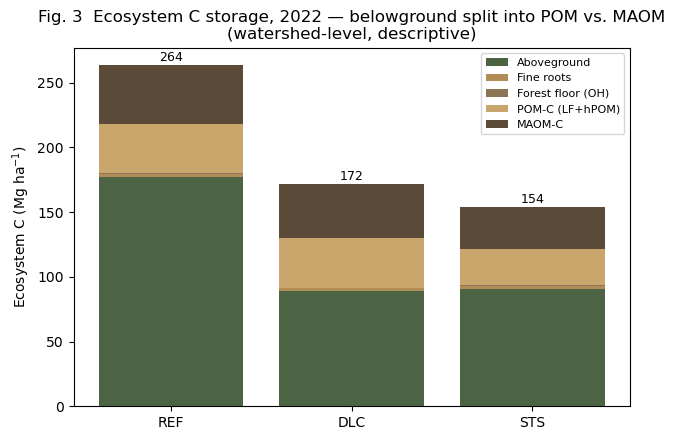

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
stack_cols = ['Aboveground', 'Fine roots', 'Forest floor (OH)', 'POM-C (LF+hPOM)', 'MAOM-C']
stack_colors = ['#4C6444', '#B08D57', '#8B7355', '#C9A66B', '#5C4A38']
bottom = np.zeros(3)
for col, c in zip(stack_cols, stack_colors):
    ax.bar(eco.index, eco[col], bottom=bottom, label=col, color=c)
    bottom += eco[col].values
for i, tot in enumerate(eco['Total']):
    ax.text(i, tot + 3, f'{tot:.0f}', ha='center', fontsize=9)
ax.set_ylabel('Ecosystem C (Mg ha$^{-1}$)')
ax.set_title('Fig. 3  Ecosystem C storage, 2022 — belowground split into POM vs. MAOM\n(watershed-level, descriptive)')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

In [30]:
def fmt(m, s):
    return f'{m:.1f} ± {s:.1f}'

r_agb = battery([agb_plot[agb_plot.watershed == w]['MgC_ha'].values for w in ORDER])
r_soil = battery([wide[wide.watershed == w]['SoilC_0_40'].values for w in ORDER])
lf_p_range = '0.004–0.013'

table1 = pd.DataFrame([
    ['AGB-C (Mg/ha)', fmt(r_agb['means'][0], r_agb['sds'][0]), fmt(r_agb['means'][1], r_agb['sds'][1]),
     fmt(r_agb['means'][2], r_agb['sds'][2]),
     f"Welch p={r_agb['pw']:.3f}; KW p={r_agb['pk']:.3f}",
     f"Dunnett DLC p={r_agb['dunnett_p'][0]:.3f}, STS p={r_agb['dunnett_p'][1]:.3f}; Levene fails -> Welch/KW lead"],
    ['Mineral soil C 0-40 cm (Mg/ha)', fmt(r_soil['means'][0], r_soil['sds'][0]),
     fmt(r_soil['means'][1], r_soil['sds'][1]), fmt(r_soil['means'][2], r_soil['sds'][2]),
     f"ANOVA p={r_soil['p']:.3f}", f"not detected; power={r_soil['power']:.2f}"],
    ['Subsoil LF-C 20-40 cm (g/m2)', f'{ref.mean():.0f}', f'{dlc.mean():.0f}',
     f'{np.nanmean(sts):.0f} (3/6 censored)', f'ANOVA p={lf_p_range} (censoring sensitivity)',
     'DLC/REF = 2.2x; Welch t p=0.007; robust to all substitution choices'],
    ['Ecosystem C total (Mg/ha)', f"{eco.loc['REF', 'Total']:.0f}", f"{eco.loc['DLC', 'Total']:.0f}",
     f"{eco.loc['STS', 'Total']:.0f}", 'descriptive (n=1 watershed/treatment)',
     f"% belowground: {eco.loc['REF', '% belowground']:.0f} / {eco.loc['DLC', '% belowground']:.0f} / {eco.loc['STS', '% belowground']:.0f}"],
], columns=['Variable', 'REF', 'DLC', 'STS', 'Primary test', 'Notes'])
table1


,Variable,REF,DLC,STS,Primary test,Notes
0,AGB-C (Mg/ha),177.4 ± 44.8,89.0 ± 14.8,90.6 ± 42.4,Welch p=0.007; KW p=0.008,"Dunnett DLC p=0.007, STS p=0.007; Levene fails..."
1,Mineral soil C 0-40 cm (Mg/ha),83.7 ± 18.8,80.4 ± 24.2,60.7 ± 10.9,ANOVA p=0.105,not detected; power=0.44
2,Subsoil LF-C 20-40 cm (g/m2),452,1010,675 (3/6 censored),ANOVA p=0.004–0.013 (censoring sensitivity),DLC/REF = 2.2x; Welch t p=0.007; robust to all...
3,Ecosystem C total (Mg/ha),264,172,154,descriptive (n=1 watershed/treatment),% belowground: 33 / 48 / 41


In [ ]:
# Dom you finished off at 02, start with 03 in the Fernow Notebooks folder tomorrow

In [7]:
NOTEBOOK_DIR = os.getcwd()
DATA_ROOT = r'.'                              # repo root (holds gdb_export/ and WV_COND_DWM_CALC.csv)
GDB = os.path.join(DATA_ROOT, 'gdb_export')

In [8]:
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
DATA_ROOT = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main'
GDB = os.path.join(DATA_ROOT, 'gdb_export')

In [10]:
# ============================== CONFIG ==============================
import os, sys
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
DATA_ROOT = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main'
GDB = os.path.join(DATA_ROOT, 'gdb_export')
SWAP_WS5_SOIL_LABELS = True     # thesis + tree map: 5 plots WS5A, 1 plot WS5B; soil file has the inverse (QC-1)
OH_STOCKS_VALID = False         # set True only after confirming OH soil_dw_g is the whole 20x20-cm frame (QC-2)
LF_CENSOR_FILL = 'half_DL'      # 'half_DL' | 'zero' | 'full_DL' for the 3 censored WS5 20-40 cm LF-C values
# ====================================================================
sys.path.insert(0, NOTEBOOK_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
from fernow_stats import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
soil = pd.read_csv(os.path.join(GDB, 'soil_samples.csv'))
frac = pd.read_csv(os.path.join(GDB, 'soil_fractions.csv'))
print(soil.shape, frac.shape)

(162, 26) (36, 34)


In [12]:
# ============================== CONFIG ==============================
import os, sys
NOTEBOOK_DIR = os.getcwd()
DATA_ROOT = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main'                             # repo root (holds gdb_export/ and WV_COND_DWM_CALC.csv)
GDB = os.path.join(DATA_ROOT, 'gdb_export')
SWAP_WS5_SOIL_LABELS = True     # thesis + tree map: 5 plots WS5A, 1 plot WS5B; soil file has the inverse (QC-1)
OH_STOCKS_VALID = False         # set True only after confirming OH soil_dw_g is the whole 20x20-cm frame (QC-2)
LF_CENSOR_FILL = 'half_DL'      # 'half_DL' | 'zero' | 'full_DL' for the 3 censored WS5 20-40 cm LF-C values
# ====================================================================
sys.path.insert(0, NOTEBOOK_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
from fernow_stats import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
soil = pd.read_csv(os.path.join(GDB, 'soil_samples.csv'))
frac = pd.read_csv(os.path.join(GDB, 'soil_fractions.csv'))
print(soil.shape, frac.shape)

(162, 26) (36, 34)


In [13]:
lab = soil[['watershed', 'soil_plot', 'soil_subcomp']].drop_duplicates()
print('As exported:'); print(lab.groupby(['watershed', 'soil_subcomp']).size().to_string())
if SWAP_WS5_SOIL_LABELS:
    sw = {'WS5a': 'WS5b', 'WS5b': 'WS5a'}
    soil['soil_subcomp'] = soil['soil_subcomp'].replace(sw); frac['soil_subcomp'] = frac['soil_subcomp'].replace(sw)
    print('\nAfter correction:'); print(soil[['watershed', 'soil_plot', 'soil_subcomp']].drop_duplicates().groupby(['watershed', 'soil_subcomp']).size().to_string())

As exported:
watershed  soil_subcomp
WS2        WS2a            5
           WS2b            1
WS4        WS4a            6
WS5        WS5a            1
           WS5b            5

After correction:
watershed  soil_subcomp
WS2        WS2a            5
           WS2b            1
WS4        WS4a            6
WS5        WS5a            5
           WS5b            1


In [14]:
oh = soil[soil.depth_code == 'OH']
print('OH dry weight per 400 cm2 frame (g):', oh.soil_dw_g.describe().round(2).to_dict())
oh_mass_Mgha = oh.wtsoil_area_gm2 / 100
oh_C_Mgha = oh.soil_C_gm2 / 100
print(f'Implied OH mass: median {oh_mass_Mgha.median():.2f} Mg/ha; OH carbon: median {oh_C_Mgha.median():.2f} Mg C/ha')

dwm_path = os.path.join(DATA_ROOT, 'WV_COND_DWM_CALC.csv'); cond_path = os.path.join(DATA_ROOT, 'WV_COND.csv')
if os.path.exists(dwm_path) and os.path.exists(cond_path):
    dwm = pd.read_csv(dwm_path, usecols=['CND_CN', 'DUFF_CARBON', 'LITTER_CARBON'])
    cc = pd.read_csv(cond_path, usecols=['CN', 'FORTYPCD', 'COND_STATUS_CD', 'CONDPROP_UNADJ'])
    hw = cc[(cc.COND_STATUS_CD == 1) & (cc.FORTYPCD.between(500, 599) | cc.FORTYPCD.between(800, 899))]
    ff = dwm.merge(hw, left_on='CND_CN', right_on='CN')
    ff_C = (ff.DUFF_CARBON.fillna(0) + ff.LITTER_CARBON.fillna(0)) * LBAC_TO_MGHA
    print(f'WV FIA hardwood duff+litter C (measured, n = {len(ff_C)}): median {ff_C.median():.1f} Mg C/ha, '
          f'10th pct {ff_C.quantile(0.10):.1f}, 90th pct {ff_C.quantile(0.90):.1f}')
    print(f'Fernow OH C median is {ff_C.median() / oh_C_Mgha.median():.0f}x below the FIA median and below the FIA '
          f'{(ff_C < oh_C_Mgha.median()).mean() * 100:.1f}th percentile.')
    print('NOTE: Fernow OH excluded fresh litter (Oi), FIA includes it — this explains a factor of ~2, not ~20-60.')
print('\nOH_STOCKS_VALID =', OH_STOCKS_VALID, '-> OH stock tests are', 'INCLUDED' if OH_STOCKS_VALID else 'EXCLUDED from inference (shown descriptively)')

OH dry weight per 400 cm2 frame (g): {'count': 54.0, 'mean': 7.42, 'std': 5.65, 'min': 0.39, '25%': 4.22, '50%': 5.97, '75%': 8.54, 'max': 27.48}
Implied OH mass: median 1.49 Mg/ha; OH carbon: median 0.43 Mg C/ha
WV FIA hardwood duff+litter C (measured, n = 2416): median 14.9 Mg C/ha, 10th pct 4.9, 90th pct 45.1
Fernow OH C median is 35x below the FIA median and below the FIA 1.9th percentile.
NOTE: Fernow OH excluded fresh litter (Oi), FIA includes it — this explains a factor of ~2, not ~20-60.

OH_STOCKS_VALID = False -> OH stock tests are EXCLUDED from inference (shown descriptively)


In [15]:
# Plot-level tables (subplots averaged first)
cols = ['soil_C_perc', 'soil_N_perc', 'soil_C_gm2', 'soil_N_gm2', 'soil_CN', 'fine_root_gm2', 'BD_gcm3', 'wtsoil_area_gm2']
sp = soil.groupby(['watershed', 'soil_plot', 'depth_code'])[cols].mean().reset_index()
W = sp.pivot_table(index=['watershed', 'soil_plot'], columns='depth_code', values=cols)
W.columns = [f'{a}|{b}' for a, b in W.columns]; W = W.reset_index()

dl = frac['LF_C_gm2'].dropna().min()
fill = {'half_DL': dl / 2, 'zero': 0.0, 'full_DL': dl}[LF_CENSOR_FILL]
frac['LF_censored'] = frac['LF_C_gm2'].isna()
frac['LF_C_f'] = frac['LF_C_gm2'].fillna(fill)
frac['POM_C'] = frac['LF_C_f'] + frac['hPOM_C_gm2']
for fr in ['LF', 'hPOM', 'MAOM']:
    frac[f'{fr}_CN'] = frac[f'{fr}_C_gm2'] / frac[f'{fr}_N_gm2']
frac['POM_share'] = frac['POM_C'] / (frac['POM_C'] + frac['MAOM_C_gm2'])
print(f'Censored LF-C values: {int(frac.LF_censored.sum())} (fill = {LF_CENSOR_FILL} = {fill:.1f} g/m2 where a C value is needed)')

results = []   # every test appends here; FDR applied at the end
def add(test, expectation, source, groups, depth=''):
    r = battery_row(test, groups, depth=depth, expectation=expectation, source=source)
    results.append(r); return r
def g3(df, col):
    return [df.loc[df.watershed == w, col].values for w in ORDER]

Censored LF-C values: 3 (fill = half_DL = 154.4 g/m2 where a C value is needed)


In [16]:
for depth in ['0-20', '20-40']:
    d = frac[frac.depth_code == depth]
    add('LF C:N', 'up (fresh residue/root inputs)', 'hypothesis; Lavallee 2020', g3(d[~d.LF_censored], 'LF_CN'), depth)
    add('hPOM C:N', 'up or ~', 'Lavallee 2020', g3(d, 'hPOM_CN'), depth)
    add('MAOM C:N', '~ (slow pool)', 'Cotrufo 2013; Lavallee 2020', g3(d, 'MAOM_CN'), depth)
print('Pooled fraction C:N (all plots) — sanity check vs. literature ordering LF > hPOM >= MAOM:')
print(frac[['LF_CN', 'hPOM_CN', 'MAOM_CN']].median().round(1).to_dict())
pd.DataFrame(results)[['test', 'depth', 'n', 'REF', 'DLC', 'STS', 'ANOVA_p', 'Welch_p', 'KW_p', 'lead_test', 'lead_p']].round(3)

Pooled fraction C:N (all plots) — sanity check vs. literature ordering LF > hPOM >= MAOM:
{'LF_CN': 41.3, 'hPOM_CN': 15.4, 'MAOM_CN': 12.2}


,test,depth,n,REF,DLC,STS,ANOVA_p,Welch_p,KW_p,lead_test,lead_p
0,LF C:N,0-20,"[6, 6, 6]",36.024,41.876,37.109,0.233,0.406,0.504,Welch,0.406
1,hPOM C:N,0-20,"[6, 6, 6]",13.408,16.477,17.787,0.295,0.195,0.173,KW,0.173
2,MAOM C:N,0-20,"[6, 6, 6]",12.387,15.395,12.719,0.022,0.034,0.032,ANOVA,0.022
3,LF C:N,20-40,"[6, 6, 3]",48.199,47.021,51.908,0.715,0.822,0.638,ANOVA,0.715
4,hPOM C:N,20-40,"[6, 6, 6]",14.403,15.713,10.222,0.162,0.200,0.135,ANOVA,0.162
5,MAOM C:N,20-40,"[6, 6, 6]",10.934,12.866,10.007,0.044,0.069,0.050,ANOVA,0.044


In [17]:
n0 = len(results); ohp = sp[sp.depth_code == 'OH']
add('OH %C', 'down (loss of forest-floor OM)', 'Nave 2010 (stocks)', g3(ohp, 'soil_C_perc'), 'OH')
add('OH C:N', 'no directional expectation', 'Peterjohn 1996 (N-saturated site)', g3(ohp, 'soil_CN'), 'OH')
if OH_STOCKS_VALID:
    add('OH C stock', 'down ~30%', 'Nave 2010', g3(ohp, 'soil_C_gm2'), 'OH')
pd.DataFrame(results[n0:])[['test', 'depth', 'REF', 'DLC', 'STS', 'ANOVA_p', 'KW_p', 'lead_test', 'lead_p']].round(3)

,test,depth,REF,DLC,STS,ANOVA_p,KW_p,lead_test,lead_p
0,OH %C,OH,32.591,27.999,29.333,0.743,0.630,ANOVA,0.743
1,OH C:N,OH,28.990,25.479,28.576,0.445,0.476,ANOVA,0.445


In [18]:
for depth in ['0-20', '20-40']:
    d = frac[frac.depth_code == depth]
    add('POM share of mineral C', 'up (new particulate inputs)', 'Nave 2010; Lavallee 2020', g3(d, 'POM_share'), depth)
d40 = frac[frac.depth_code == '20-40'].copy()
for name, val in [('zero', 0.0), ('half_DL', dl / 2), ('full_DL', dl)]:
    lf = d40['LF_C_gm2'].fillna(val); share = (lf + d40.hPOM_C_gm2) / (lf + d40.hPOM_C_gm2 + d40.MAOM_C_gm2)
    r = battery([share[d40.watershed == w].values for w in ORDER])
    print(f'20-40 POM share, censor fill = {name:8s}: means {np.round(r["means"], 3)}  ANOVA p = {r["p"]:.4f}  KW p = {r["pk"]:.4f}')

20-40 POM share, censor fill = zero    : means [0.373 0.465 0.266]  ANOVA p = 0.0702  KW p = 0.0644
20-40 POM share, censor fill = half_DL : means [0.373 0.465 0.32 ]  ANOVA p = 0.1272  KW p = 0.0745
20-40 POM share, censor fill = full_DL : means [0.373 0.465 0.362]  ANOVA p = 0.2169  KW p = 0.1661


0-20: pooled Spearman rho = +0.40 (p = 0.104); within-watershed rho = +0.26 (p = 0.333, df = 14), n = 18
20-40: pooled Spearman rho = +0.54 (p = 0.040); within-watershed rho = +0.09 (p = 0.781, df = 11), n = 15


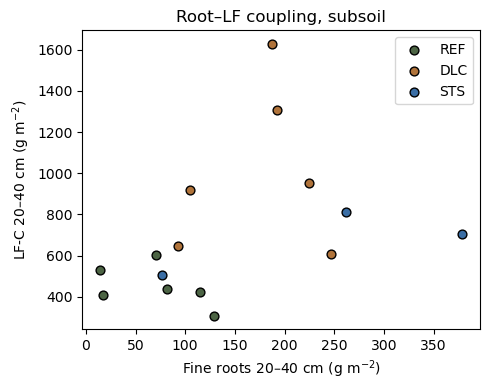

In [19]:
fr = W[['watershed', 'soil_plot', 'fine_root_gm2|0-20', 'fine_root_gm2|20-40']]
m = frac.merge(fr, on=['watershed', 'soil_plot'])
for depth in ['0-20', '20-40']:
    d = m[(m.depth_code == depth) & (~m.LF_censored)].rename(columns={f'fine_root_gm2|{depth}': 'roots'})
    rp = stats.spearmanr(d.roots, d.LF_C_gm2)
    rw, pw, dfree = within_group_corr(d, 'roots', 'LF_C_gm2', method='spearman')
    print(f'{depth}: pooled Spearman rho = {rp.correlation:+.2f} (p = {rp.pvalue:.3f}); within-watershed rho = {rw:+.2f} (p = {pw:.3f}, df = {dfree}), n = {len(d)}')
    add('Fine roots', 'down (fewer live trees)', 'mechanistic expectation', g3(W, f'fine_root_gm2|{depth}'), depth)
fig, ax = plt.subplots(figsize=(5, 4))
d = m[(m.depth_code == '20-40') & (~m.LF_censored)]
for w in ORDER:
    s = d[d.watershed == w]; ax.scatter(s['fine_root_gm2|20-40'], s.LF_C_gm2, color=COLORS[w], label=LABELS[w], s=40, edgecolor='k')
ax.set_xlabel('Fine roots 20–40 cm (g m$^{-2}$)'); ax.set_ylabel('LF-C 20–40 cm (g m$^{-2}$)'); ax.legend()
ax.set_title('Root–LF coupling, subsoil'); plt.tight_layout(); plt.show()

In [20]:
W['strat_conc'] = W['soil_C_perc|0-20'] / W['soil_C_perc|20-40']
W['strat_stock'] = W['soil_C_gm2|0-20'] / W['soil_C_gm2|20-40']
W['subsoil_share'] = W['soil_C_gm2|20-40'] / (W['soil_C_gm2|0-20'] + W['soil_C_gm2|20-40'])
add('C stratification ratio (conc.)', 'down (profile mixing / deep inputs)', 'hypothesis; Franzluebbers 2002', g3(W, 'strat_conc'), '0-20/20-40')
add('Subsoil share of 0-40 C stock', 'up', 'hypothesis', g3(W, 'subsoil_share'), '20-40 / 0-40')
pd.DataFrame(results[-2:])[['test', 'REF', 'DLC', 'STS', 'ANOVA_p', 'Welch_p', 'KW_p', 'lead_test', 'lead_p']].round(3)

,test,REF,DLC,STS,ANOVA_p,Welch_p,KW_p,lead_test,lead_p
0,C stratification ratio (conc.),3.175,2.545,3.465,0.349,0.406,0.484,ANOVA,0.349
1,Subsoil share of 0-40 C stock,0.296,0.352,0.306,0.390,0.550,0.459,Welch,0.550


In [21]:
M1 = W['wtsoil_area_gm2|0-20']; M2 = W['wtsoil_area_gm2|20-40']
C1 = W['soil_C_gm2|0-20']; C2 = W['soil_C_gm2|20-40']
ref20, ref40 = M1.min(), (M1 + M2).min()
def c_at(mref, M1, M2, C1, C2):
    return np.where(mref <= M1, C1 * mref / M1, C1 + C2 * (mref - M1) / M2)
W['C_ESM_20'] = c_at(ref20, M1, M2, C1, C2) / 100
W['C_ESM_40'] = c_at(ref40, M1, M2, C1, C2) / 100
W['C_FD_40'] = (C1 + C2) / 100
print(f'Reference masses: {ref20 / 1000:.0f} kg/m2 (~0-20), {ref40 / 1000:.0f} kg/m2 (~0-40)')
add('Mineral soil C, fixed depth 0-40 (Mg/ha)', 'down or ~', 'Nave 2010; James & Harrison 2016', g3(W, 'C_FD_40'), '0-40 FD')
add('Mineral soil C, ESM ~0-40 (Mg/ha)', 'down or ~', 'von Haden 2020 (method)', g3(W, 'C_ESM_40'), '0-40 ESM')
add('Mineral soil C, ESM ~0-20 (Mg/ha)', 'down or ~', 'von Haden 2020 (method)', g3(W, 'C_ESM_20'), '0-20 ESM')
pd.DataFrame(results[-3:])[['test', 'REF', 'DLC', 'STS', 'ANOVA_p', 'KW_p', 'power', 'lead_test', 'lead_p']].round(3)

Reference masses: 101 kg/m2 (~0-20), 264 kg/m2 (~0-40)


,test,REF,DLC,STS,ANOVA_p,KW_p,power,lead_test,lead_p
0,"Mineral soil C, fixed depth 0-40 (Mg/ha)",83.736,80.373,60.747,0.105,0.114,0.442,ANOVA,0.105
1,"Mineral soil C, ESM ~0-40 (Mg/ha)",77.227,66.749,51.649,0.070,0.058,0.521,ANOVA,0.070
2,"Mineral soil C, ESM ~0-20 (Mg/ha)",44.721,32.119,28.938,0.042,0.047,0.617,ANOVA,0.042


In [22]:
add('Bulk density', 'up (compaction)', 'Cambi 2015', g3(W, 'BD_gcm3|0-20'), '0-20')
add('Bulk density', 'up or ~', 'Cambi 2015', g3(W, 'BD_gcm3|20-40'), '20-40')
pd.DataFrame(results[-2:])[['test', 'depth', 'REF', 'DLC', 'STS', 'ANOVA_p', 'KW_p', 'lead_test', 'lead_p']].round(3)

,test,depth,REF,DLC,STS,ANOVA_p,KW_p,lead_test,lead_p
0,Bulk density,0-20,0.678,0.840,0.766,0.196,0.291,ANOVA,0.196
1,Bulk density,20-40,0.876,1.029,1.097,0.097,0.149,ANOVA,0.097


In [23]:
ss = pd.read_csv(os.path.join(GDB, 'ssurgo_plot.csv')).merge(pd.read_csv(os.path.join(GDB, 'plots_study.csv'))[['plot_id', 'watershed']], on='plot_id')
for depth, sfx in [('0-20', '0_20'), ('20-40', '20_40')]:
    fine = (ss[f'silttotal_r_{sfx}'] + ss[f'claytotal_r_{sfx}']).groupby(ss.watershed).mean()
    cap = 4.09 + 0.37 * fine
    d = frac[frac.depth_code == depth].merge(W[['watershed', 'soil_plot', f'wtsoil_area_gm2|{depth}']], on=['watershed', 'soil_plot'])
    d['MAOC_gkg'] = d.MAOM_C_gm2 / (d[f'wtsoil_area_gm2|{depth}'] / 1000)
    out = d.groupby('watershed').MAOC_gkg.mean().to_frame().join(cap.rename('capacity_gkg'))
    out['saturation_ratio'] = out.MAOC_gkg / out.capacity_gkg
    out.index = [LABELS[w] for w in out.index]
    print(f'\n{depth} cm'); print(out.reindex(['REF', 'DLC', 'STS']).round(2))


0-20 cm
     MAOC_gkg  capacity_gkg  saturation_ratio
REF     18.16         29.03              0.63
DLC     18.56         31.19              0.59
STS     15.47         31.99              0.48

20-40 cm
     MAOC_gkg  capacity_gkg  saturation_ratio
REF      8.15         29.92              0.27
DLC      8.06         32.80              0.25
STS      5.23         33.13              0.16


In [26]:
S = pd.DataFrame(results)
S['lead_p_FDR'] = bh_fdr(S.lead_p)
def direction(r):
    d = [np.sign(r.DLC - r.REF), np.sign(r.STS - r.REF)]
    return {2: 'up', -2: 'down'}.get(int(sum(d)), 'mixed')
S['observed'] = S.apply(direction, axis=1)
def verdict(r):
    exp = r.expectation.split()[0]
    if exp in ('up', 'down'):
        if r.observed == exp and r.lead_p_FDR < 0.05: return 'consistent'
        if r.observed == exp and r.lead_p < 0.10: return 'consistent (trend)'
        if r.observed not in (exp, 'mixed') and r.lead_p < 0.05: return 'opposite'
        if r.observed not in (exp, 'mixed') and r.lead_p < 0.10: return 'opposite (trend)'
    if exp == '~':
        return 'consistent (no change)' if r.lead_p >= 0.10 else ('UNEXPECTED change' if r.lead_p < 0.05 else 'trend where none expected')
    if exp in ('up', 'down') and r.lead_p < 0.05 and r.observed == 'mixed': return 'differs, direction mixed'
    return 'not detected'
S['verdict'] = S.apply(verdict, axis=1)
S.to_csv(os.path.join(NOTEBOOK_DIR, 'soil_mechanism_tests.csv'), index=False)
S[['test', 'depth', 'expectation', 'source', 'REF', 'DLC', 'STS', 'observed', 'lead_test', 'lead_p', 'lead_p_FDR', 'power', 'verdict']].round(3)

,test,depth,expectation,source,REF,DLC,STS,observed,lead_test,lead_p,lead_p_FDR,power,verdict
0,LF C:N,0-20,up (fresh residue/root inputs),hypothesis; Lavallee 2020,36.024,41.876,37.109,up,Welch,0.406,0.593,0.286,not detected
1,hPOM C:N,0-20,up or ~,Lavallee 2020,13.408,16.477,17.787,up,KW,0.173,0.329,0.242,not detected
2,MAOM C:N,0-20,~ (slow pool),Cotrufo 2013; Lavallee 2020,12.387,15.395,12.719,up,ANOVA,0.022,0.279,0.726,UNEXPECTED change
3,LF C:N,20-40,up (fresh residue/root inputs),hypothesis; Lavallee 2020,48.199,47.021,51.908,mixed,ANOVA,0.715,0.830,0.101,not detected
4,hPOM C:N,20-40,up or ~,Lavallee 2020,14.403,15.713,10.222,mixed,ANOVA,0.162,0.329,0.356,not detected
5,MAOM C:N,20-40,~ (slow pool),Cotrufo 2013; Lavallee 2020,10.934,12.866,10.007,mixed,ANOVA,0.044,0.279,0.608,UNEXPECTED change
6,OH %C,OH,down (loss of forest-floor OM),Nave 2010 (stocks),32.591,27.999,29.333,down,ANOVA,0.743,0.830,0.090,not detected
7,OH C:N,OH,no directional expectation,Peterjohn 1996 (N-saturated site),28.990,25.479,28.576,down,ANOVA,0.445,0.604,0.170,not detected
8,POM share of mineral C,0-20,up (new particulate inputs),Nave 2010; Lavallee 2020,0.466,0.484,0.507,up,ANOVA,0.857,0.905,0.070,not detected
9,POM share of mineral C,20-40,up (new particulate inputs),Nave 2010; Lavallee 2020,0.373,0.465,0.320,mixed,ANOVA,0.127,0.302,0.405,not detected


In [25]:
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'

In [28]:
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
GDB = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main\gdb_export'

In [30]:
FIA_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main'

In [31]:
import os, glob
d = r'C:\Users\DCifelli2\Downloads\WV_CSV'
print(os.path.exists(d))
print([os.path.basename(f) for f in glob.glob(d + r'\**\WV_PLOT*', recursive=True)])
print(sorted(os.listdir(d))[:20])

True
['WV_PLOT.csv', 'WV_PLOTGEOM.csv', 'WV_PLOTSNAP.csv', 'WV_PLOT_REGEN.csv']
['WV_COND.csv', 'WV_COND_DWM_CALC.csv', 'WV_COUNTY.csv', 'WV_DWM_COARSE_WOODY_DEBRIS.csv', 'WV_DWM_DUFF_LITTER_FUEL.csv', 'WV_DWM_FINE_WOODY_DEBRIS.csv', 'WV_DWM_MICROPLOT_FUEL.csv', 'WV_DWM_RESIDUAL_PILE.csv', 'WV_DWM_TRANSECT_SEGMENT.csv', 'WV_DWM_VISIT.csv', 'WV_FVS_GROUPADDFILESANDKEYWORDS.csv', 'WV_FVS_PLOTINIT_PLOT.csv', 'WV_FVS_STANDINIT_COND.csv', 'WV_FVS_STANDINIT_PLOT.csv', 'WV_FVS_TREEINIT_COND.csv', 'WV_FVS_TREEINIT_PLOT.csv', 'WV_GRND_CVR.csv', 'WV_INVASIVE_SUBPLOT_SPP.csv', 'WV_LICHEN_LAB.csv', 'WV_LICHEN_PLOT_SUMMARY.csv']


In [32]:
# ============================== CONFIG ==============================
import os, sys
NOTEBOOK_DIR = os.getcwd()
FIA_DIR = r'.'                         # folder with WV_*.csv, or the filtered folder from notebook 00 (WV_*.csv.gz)
GDB = os.path.join(r'.', 'gdb_export')  # Fernow tables (for comparison values)
FERNOW_LATLON = (39.06, -79.68)
HARDWOOD = [(500, 599), (800, 899)]     # oak/hickory, maple/beech/birch forest-type groups
MIN_INVYR = 2004                         # annual inventory only (periodic 1989/2000 lack treatment codes)
FERNOW_SECTION = None                    # None = derive from FIA plots within 15 km of Fernow
EXPORT_TO_GDB = False                    # §6: write latest-visit FIA plots to the ArcGIS Pro default geodatabase
# ====================================================================
sys.path.insert(0, NOTEBOOK_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
from fernow_stats import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
QC = []
def qc(step, df):
    QC.append((step, len(df))); print(f'[QC] {step}: {len(df):,} rows')
def fia(name):
    # path to WV_<name>.csv.gz (filtered by notebook 00) or WV_<name>.csv (raw); None if absent
    for ext in ('.csv.gz', '.csv'):
        p = os.path.join(FIA_DIR, f'WV_{name}{ext}')
        if os.path.exists(p): return p
    return None
for t in ['PLOT', 'COND', 'PLOTGEOM', 'COND_DWM_CALC']:
    assert fia(t), f'missing WV_{t}(.csv/.csv.gz) in FIA_DIR'
print('FIA files found:', {t: (os.path.basename(fia(t)) if fia(t) else None) for t in ['PLOT', 'COND', 'PLOTGEOM', 'COND_DWM_CALC', 'TREE', 'SEEDLING']})

<class 'AssertionError'>: missing WV_PLOT(.csv/.csv.gz) in FIA_DIR

In [33]:
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
FIA_DIR = r'C:\Users\DCifelli2\Downloads\WV_CSV'
GDB = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main\gdb_export'

In [34]:
print(FIA_DIR)

C:\Users\DCifelli2\Downloads\WV_CSV


In [35]:
# ============================== CONFIG ==============================
import os, sys
NOTEBOOK_DIR = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Fernow_Notebooks'
FIA_DIR = r'C:\Users\DCifelli2\Downloads\WV_CSV'
GDB = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Desktop\Forest-Management-Carbon-main\gdb_export'
FERNOW_LATLON = (39.06, -79.68)
HARDWOOD = [(500, 599), (800, 899)]     # oak/hickory, maple/beech/birch forest-type groups
MIN_INVYR = 2004                         # annual inventory only (periodic 1989/2000 lack treatment codes)
FERNOW_SECTION = None                    # None = derive from FIA plots within 15 km of Fernow
EXPORT_TO_GDB = False                    # §6: write latest-visit FIA plots to the ArcGIS Pro default geodatabase
# ====================================================================
sys.path.insert(0, NOTEBOOK_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
from fernow_stats import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
QC = []
def qc(step, df):
    QC.append((step, len(df))); print(f'[QC] {step}: {len(df):,} rows')
def fia(name):
    # path to WV_<name>.csv.gz (filtered by notebook 00) or WV_<name>.csv (raw); None if absent
    for ext in ('.csv.gz', '.csv'):
        p = os.path.join(FIA_DIR, f'WV_{name}{ext}')
        if os.path.exists(p): return p
    return None
for t in ['PLOT', 'COND', 'PLOTGEOM', 'COND_DWM_CALC']:
    assert fia(t), f'missing WV_{t}(.csv/.csv.gz) in FIA_DIR'
print('FIA files found:', {t: (os.path.basename(fia(t)) if fia(t) else None) for t in ['PLOT', 'COND', 'PLOTGEOM', 'COND_DWM_CALC', 'TREE', 'SEEDLING']})

FIA files found: {'PLOT': 'WV_PLOT.csv', 'COND': 'WV_COND.csv', 'PLOTGEOM': 'WV_PLOTGEOM.csv', 'COND_DWM_CALC': 'WV_COND_DWM_CALC.csv', 'TREE': 'WV_TREE.csv', 'SEEDLING': 'WV_SEEDLING.csv'}


In [36]:
P = pd.read_csv(fia('PLOT'), low_memory=False,
                usecols=['CN', 'INVYR', 'COUNTYCD', 'PLOT', 'PLOT_STATUS_CD', 'MEASYEAR', 'LAT', 'LON', 'ELEV', 'PREV_PLT_CN', 'REMPER'])
C = pd.read_csv(fia('COND'), low_memory=False,
                usecols=['CN', 'PLT_CN', 'INVYR', 'CONDID', 'COND_STATUS_CD', 'CONDPROP_UNADJ', 'FORTYPCD', 'STDAGE', 'STDORGCD',
                         'SITECLCD', 'SLOPE', 'ASPECT', 'OWNGRPCD', 'BALIVE', 'DSTRBCD1', 'DSTRBCD2', 'DSTRBCD3',
                         'TRTCD1', 'TRTCD2', 'TRTCD3', 'TRTYR1', 'TRTYR2', 'TRTYR3',
                         'CARBON_DOWN_DEAD', 'CARBON_LITTER', 'CARBON_SOIL_ORG', 'CARBON_UNDERSTORY_AG', 'CARBON_UNDERSTORY_BG'])
G = pd.read_csv(fia('PLOTGEOM'), low_memory=False, usecols=['CN', 'ECOSUBCD'])
G['ECOSUBCD'] = G.ECOSUBCD.astype(str).str.strip(); G['SECTION'] = G.ECOSUBCD.str[:5]
qc('COND all', C)

c = C[C.INVYR >= MIN_INVYR]; qc(f'annual inventory (INVYR >= {MIN_INVYR})', c)
c = c[c.COND_STATUS_CD == 1]; qc('accessible forest land', c)
hw = np.zeros(len(c), bool)
for lo, hi in HARDWOOD: hw |= c.FORTYPCD.between(lo, hi).values
c = c[hw]; qc('hardwood forest types (500s, 800s)', c)
c = c[c.STDORGCD.fillna(0) == 0]; qc('natural origin (not planted)', c)

def prep(df):
    df = df.merge(P.rename(columns={'CN': 'PLT_CN', 'INVYR': 'INVYR_P'}), on='PLT_CN')
    df = df.merge(G.rename(columns={'CN': 'PLT_CN'}), on='PLT_CN', how='left')
    df['pid'] = df.COUNTYCD.astype(str) + '_' + df.PLOT.astype(str)
    df['elev_m'] = df.ELEV * 0.3048
    df['slope_pct'] = df.SLOPE
    df['northness'] = np.where(df.SLOPE > 0, np.cos(np.deg2rad(df.ASPECT)), 0.0)
    df['cut'] = (df[['TRTCD1', 'TRTCD2', 'TRTCD3']] == 10).any(axis=1)
    df['disturbed'] = (df[['DSTRBCD1', 'DSTRBCD2', 'DSTRBCD3']].fillna(0) > 0).any(axis=1)
    trt_yr = df[['TRTYR1', 'TRTYR2', 'TRTYR3']].where(df[['TRTCD1', 'TRTCD2', 'TRTCD3']].values == 10)
    df['yrs_since_cut'] = np.where(df.cut, df.MEASYEAR - trt_yr.max(axis=1), np.nan)
    df['ftgroup'] = np.where(df.FORTYPCD < 600, 'oak/hickory', 'maple/beech/birch')
    return df

c_multi = prep(c.copy())   # all hardwood conditions incl. partial ones — used for per-acre DWM carbon (§4)
print(f'   BALIVE max before single-condition filter: {c.BALIVE.max():.0f} ft2/ac (artifact of tiny partial conditions)')
c = c[c.CONDPROP_UNADJ == 1]; qc('single-condition plots (CONDPROP_UNADJ = 1) — for BALIVE analyses', c)
print(f'   BALIVE max after: {c.BALIVE.max():.0f} ft2/ac')
c = prep(c)

c_multi['in_section'] = False
if FERNOW_SECTION is None:
    d_km = np.hypot((c.LAT - FERNOW_LATLON[0]) * 111.0, (c.LON - FERNOW_LATLON[1]) * 86.0)
    FERNOW_SECTION = c.loc[d_km < 15, 'SECTION'].mode().iat[0]
    print(f'Fernow ecological section (mode of FIA plots within 15 km): {FERNOW_SECTION}; subsections nearby:',
          c.loc[d_km < 15, 'ECOSUBCD'].value_counts().head(3).to_dict())
c['in_section'] = c.SECTION == FERNOW_SECTION; c_multi['in_section'] = c_multi.SECTION == FERNOW_SECTION

latest = c.sort_values('INVYR').groupby('pid').tail(1).copy(); qc('latest visit per plot (cross-sectional sample)', latest)
print(f"Latest-visit: {latest.cut.sum()} with cutting recorded; {latest.in_section.sum()} in section {FERNOW_SECTION}")

[QC] COND all: 21,227 rows
[QC] annual inventory (INVYR >= 2004): 14,280 rows
[QC] accessible forest land: 8,829 rows
[QC] hardwood forest types (500s, 800s): 7,926 rows
[QC] natural origin (not planted): 7,896 rows
   BALIVE max before single-condition filter: 1963 ft2/ac (artifact of tiny partial conditions)
[QC] single-condition plots (CONDPROP_UNADJ = 1) — for BALIVE analyses: 4,199 rows
   BALIVE max after: 267 ft2/ac
Fernow ecological section (mode of FIA plots within 15 km): M221B; subsections nearby: {'M221Bb': 72, 'M221Ba': 44}
[QC] latest visit per plot (cross-sectional sample): 1,622 rows
Latest-visit: 74 with cutting recorded; 574 in section M221B


In [37]:
# Fernow comparison values (2022 plots). FIA BALIVE includes live trees >= 1.0 in; Fernow trees also >= 1.0 in.
ft = pd.read_csv(os.path.join(GDB, 'trees.csv')); ft = ft[ft.dbh_cm.notna()]
PLOT_AC = 0.1
fplot = (ft.groupby(['watershed', 'plot_id']).ba_m2.sum() * 10.7639 / PLOT_AC).rename('BA_ft2ac').reset_index()
ter = pd.read_csv(os.path.join(GDB, 'plot_terrain.csv'))[['plot_id', 'dem5_fp', 'slope5_fp']]
fplot = fplot.merge(ter, on='plot_id')
fplot['slope_pct'] = np.tan(np.deg2rad(fplot.slope5_fp)) * 100
FER = fplot.groupby('watershed')[['BA_ft2ac', 'dem5_fp', 'slope_pct']].mean().reindex(ORDER)
FER.index = [LABELS[w] for w in FER.index]
FER.round(1)

,BA_ft2ac,dem5_fp,slope_pct
REF,183.8,829.9,16.5
DLC,116.5,759.1,38.3
STS,115.8,778.7,31.4


In [38]:
def pct(x, dist): return stats.percentileofscore(dist.dropna(), x, kind='mean')
uncut = latest[~latest.cut]; cutd = latest[latest.cut]
old = uncut[uncut.STDAGE >= 80]
rows = []
for lab, frame in [('WV', latest), (FERNOW_SECTION, latest[latest.in_section])]:
    u, k, o = frame[~frame.cut], frame[frame.cut], frame[(~frame.cut) & (frame.STDAGE >= 80)]
    rows.append(dict(frame=lab, n_uncut=len(u), n_uncut_age80=len(o), n_cut=len(k),
                     REF_pct_vs_uncut=pct(FER.loc['REF', 'BA_ft2ac'], u.BALIVE),
                     REF_pct_vs_uncut_age80=pct(FER.loc['REF', 'BA_ft2ac'], o.BALIVE),
                     DLC_pct_vs_cut=pct(FER.loc['DLC', 'BA_ft2ac'], k.BALIVE),
                     STS_pct_vs_cut=pct(FER.loc['STS', 'BA_ft2ac'], k.BALIVE),
                     uncut_median_BA=u.BALIVE.median(), cut_median_BA=k.BALIVE.median(),
                     REF_elev_pct=pct(FER.loc['REF', 'dem5_fp'], frame.elev_m), DLC_elev_pct=pct(FER.loc['DLC', 'dem5_fp'], frame.elev_m)))
rep = pd.DataFrame(rows); rep.round(1)

,frame,n_uncut,n_uncut_age80,n_cut,REF_pct_vs_uncut,REF_pct_vs_uncut_age80,DLC_pct_vs_cut,STS_pct_vs_cut,uncut_median_BA,cut_median_BA,REF_elev_pct,DLC_elev_pct
0,WV,1548,798,74,92.1,88.2,82.4,81.1,120.5,79.0,75.2,68.9
1,M221B,557,368,17,84.4,81.0,76.5,76.5,138.6,88.7,39.2,30.0


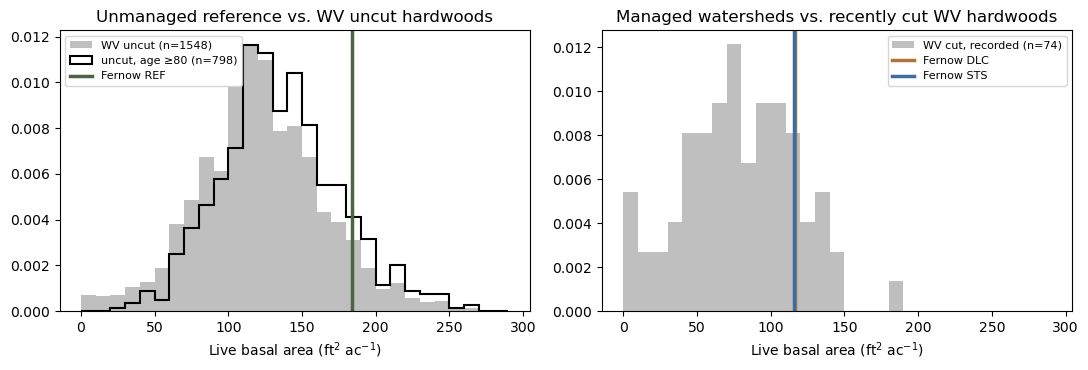

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.arange(0, 300, 10)
ax[0].hist(uncut.BALIVE, bins, color='0.75', label=f'WV uncut (n={len(uncut)})', density=True)
ax[0].hist(old.BALIVE, bins, histtype='step', color='k', lw=1.5, label=f'uncut, age ≥80 (n={len(old)})', density=True)
ax[0].axvline(FER.loc['REF', 'BA_ft2ac'], color=COLORS['WS4'], lw=2.5, label='Fernow REF')
ax[1].hist(cutd.BALIVE, bins, color='0.75', label=f'WV cut, recorded (n={len(cutd)})', density=True)
for w in ['WS2', 'WS5']:
    ax[1].axvline(FER.loc[LABELS[w], 'BA_ft2ac'], color=COLORS[w], lw=2.5, label=f'Fernow {LABELS[w]}')
for a in ax: a.set_xlabel('Live basal area (ft$^2$ ac$^{-1}$)'); a.legend(fontsize=8)
ax[0].set_title('Unmanaged reference vs. WV uncut hardwoods'); ax[1].set_title('Managed watersheds vs. recently cut WV hardwoods')
plt.tight_layout(); plt.show()

In [40]:
def design(df):
    X = [df.cut.astype(float).values, df.elev_m.values, df.slope_pct.values, df.northness.values,
         (df.ftgroup == 'maple/beech/birch').astype(float).values]
    names = ['cut', 'elev_m', 'slope_pct', 'northness', 'maple_beech_birch']
    for s in sorted(df.SITECLCD.dropna().unique())[1:]:
        X.append((df.SITECLCD == s).astype(float).values); names.append(f'siteclass_{int(s)}')
    return X, names
out = []
for lab, frame in [('WV', latest), (FERNOW_SECTION, latest[latest.in_section])]:
    f = frame.dropna(subset=['BALIVE', 'elev_m', 'slope_pct', 'SITECLCD'])
    X, names = design(f); m = ols(f.BALIVE.values, X, names)
    b = m['table'].loc['cut']; base = f.loc[~f.cut, 'BALIVE'].mean()
    out.append(dict(frame=lab, n=len(f), n_cut=int(f.cut.sum()), cut_effect_ft2ac=b.coef,
                    CI_lo=b.coef - 1.96 * b.SE_HC3, CI_hi=b.coef + 1.96 * b.SE_HC3, p_HC3=b.p_HC3,
                    pct_of_uncut_mean=b.coef / base * 100, R2=m['r2']))
reg = pd.DataFrame(out)
fern = (FER.loc[['DLC', 'STS'], 'BA_ft2ac'] / FER.loc['REF', 'BA_ft2ac'] - 1) * 100
print('Fernow plot-based BA difference vs REF (%):', fern.round(0).to_dict())
reg.round(2)

Fernow plot-based BA difference vs REF (%): {'DLC': -37.0, 'STS': -37.0}


,frame,n,n_cut,cut_effect_ft2ac,CI_lo,CI_hi,p_HC3,pct_of_uncut_mean,R2
0,WV,1622,74,-39.14,-48.79,-29.48,0.0,-32.01,0.19
1,M221B,574,17,-52.52,-71.63,-33.42,0.0,-37.63,0.16


In [41]:
# Effect by years since cutting (0-6 yr window available in FIA)
k = latest[latest.cut].copy()
k['ysc_bin'] = pd.cut(k.yrs_since_cut, [-0.1, 2, 4, 7], labels=['0-2', '3-4', '5-7'])
print(k.groupby('ysc_bin').BALIVE.agg(['count', 'median', 'mean']).round(1))
print(f'Uncut median BALIVE: {uncut.BALIVE.median():.1f}')

         count  median  mean
ysc_bin                     
0-2         36    66.3  71.6
3-4         25    78.7  81.8
5-7         13   102.5  96.2
Uncut median BALIVE: 120.5


In [42]:
prev = C[['PLT_CN', 'CONDID', 'BALIVE', 'CONDPROP_UNADJ', 'COND_STATUS_CD', 'TRTCD1', 'TRTCD2', 'TRTCD3',
          'DSTRBCD1', 'DSTRBCD2', 'DSTRBCD3']].copy()
prev['cut0'] = (prev[['TRTCD1', 'TRTCD2', 'TRTCD3']] == 10).any(axis=1)
prev['dist0'] = (prev[['DSTRBCD1', 'DSTRBCD2', 'DSTRBCD3']].fillna(0) > 0).any(axis=1)
prev = prev.rename(columns={'PLT_CN': 'PREV_PLT_CN', 'BALIVE': 'BA0', 'CONDPROP_UNADJ': 'CP0', 'COND_STATUS_CD': 'CS0'})
pairs = c.merge(prev[['PREV_PLT_CN', 'CONDID', 'BA0', 'CP0', 'CS0', 'cut0', 'dist0']], on=['PREV_PLT_CN', 'CONDID'])
pairs = pairs[(pairs.CP0 == 1) & (pairs.CS0 == 1) & (pairs.REMPER > 0)]; qc('remeasured single-condition pairs', pairs)
pairs['dBA'] = (pairs.BALIVE - pairs.BA0) / pairs.REMPER
pairs['group'] = np.select([pairs.cut, pairs.cut0 & ~pairs.cut, ~pairs.cut & ~pairs.cut0 & ~pairs.disturbed & ~pairs.dist0],
                           ['cut in interval', 'recovering', 'undisturbed'], 'other disturbance')
lp = pairs.sort_values('INVYR').groupby('pid').tail(1); qc('one pair per plot (latest)', lp)
print(lp.groupby('group').dBA.describe()[['count', '50%', 'mean', 'std']].round(2))

[QC] remeasured single-condition pairs: 2,436 rows
[QC] one pair per plot (latest): 1,248 rows
                   count   50%  mean   std
group                                     
cut in interval     56.0 -4.83 -6.01  6.24
other disturbance  566.0  0.92  0.61  2.19
recovering          56.0  2.23  1.95  1.61
undisturbed        570.0  1.20  1.09  1.83


In [43]:
und = lp[lp.group == 'undisturbed'].copy()
und['bin'] = pd.cut(und.BA0, [0, 60, 90, 120, 150, 180, 300])
tab = und.groupby('bin').dBA.agg(['count', 'median']).assign(
    CI=lambda t: [np.round(boot_ci(und.loc[und.bin == b, 'dBA'].values), 2) for b in t.index])
print('Undisturbed stands: annual change in live BA by starting BA (ft2/ac/yr)'); print(tab)
m = ols(und.dBA.values, [und.BA0.values], ['BA0'])
b0, b1 = m['table'].coef
print(f'\nOLS dBA = {b0:.2f} + {b1:.4f} x BA0 (HC3 p = {m["table"].loc["BA0", "p_HC3"]:.2e}, R2 = {m["r2"]:.3f}); '
      f'BA at zero net change (extrapolated) ~ {-b0 / b1:.0f} ft2/ac')
hi = und[und.BA0 >= 180].dBA
print(f'Stands starting >=180 ft2/ac (REF-like): median {hi.median():.2f} ft2/ac/yr, 95% CI {np.round(boot_ci(hi.values), 2)}, '
      f'{(hi > 0).mean() * 100:.0f}% gained BA, n = {len(hi)}')
rec = lp[lp.group == 'recovering'].dBA; comp = und[und.BA0.between(40, 110)].dBA
print(f'Recovering stands: median {rec.median():.2f} (n = {len(rec)}); undisturbed stands at similar starting BA (40-110): '
      f'median {comp.median():.2f}; Mann-Whitney p = {stats.mannwhitneyu(rec, comp).pvalue:.3f}')

Undisturbed stands: annual change in live BA by starting BA (ft2/ac/yr)
            count    median            CI
bin                                      
(0, 60]        41  1.832020  [1.52, 2.44]
(60, 90]       90  1.611933  [1.18, 1.89]
(90, 120]     151  1.179811  [1.04, 1.52]
(120, 150]    154  1.179587  [0.96, 1.43]
(150, 180]     89  0.795393  [0.31, 1.24]
(180, 300]     44  0.643464  [0.12, 1.39]

OLS dBA = 2.23 + -0.0094 x BA0 (HC3 p = 1.76e-06, R2 = 0.046); BA at zero net change (extrapolated) ~ 236 ft2/ac
Stands starting >=180 ft2/ac (REF-like): median 0.64 ft2/ac/yr, 95% CI [0.12 1.39], 68% gained BA, n = 44
Recovering stands: median 2.23 (n = 56); undisturbed stands at similar starting BA (40-110): median 1.52; Mann-Whitney p = 0.025


Run notebook 02 first to overlay the Fernow census intervals.


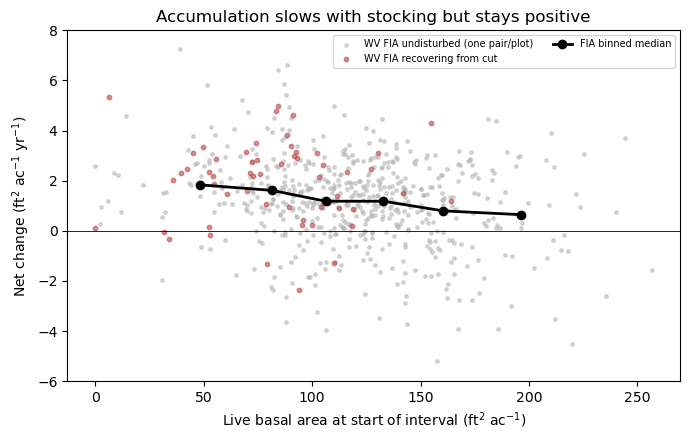

In [44]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(und.BA0, und.dBA, s=6, color='0.7', alpha=0.5, label='WV FIA undisturbed (one pair/plot)')
rp = lp[lp.group == 'recovering']; ax.scatter(rp.BA0, rp.dBA, s=10, color='#bc4749', alpha=0.6, label='WV FIA recovering from cut')
med = und.groupby('bin').agg(x=('BA0', 'median'), y=('dBA', 'median'))
ax.plot(med.x, med.y, 'k-o', lw=2, label='FIA binned median')
pth = os.path.join(NOTEBOOK_DIR, 'fernow_census_periods.csv')
if os.path.exists(pth):
    fp = pd.read_csv(pth)
    for w in ORDER:
        d = fp[fp.watershed == w]; ax.scatter(d.BA0_ft2ac, d.rate_BA_ft2ac, s=60, marker='D', color=COLORS[w], edgecolor='k', label=f'Fernow census {LABELS[w]}')
else:
    print('Run notebook 02 first to overlay the Fernow census intervals.')
ax.axhline(0, color='k', lw=0.6); ax.set_ylim(-6, 8)
ax.set_xlabel('Live basal area at start of interval (ft$^2$ ac$^{-1}$)'); ax.set_ylabel('Net change (ft$^2$ ac$^{-1}$ yr$^{-1}$)')
ax.set_title('Accumulation slows with stocking but stays positive'); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

In [45]:
D = pd.read_csv(fia('COND_DWM_CALC'), low_memory=False,
                usecols=['CND_CN', 'DUFF_CARBON', 'LITTER_CARBON', 'CWD_CARBON_COND', 'FWD_SM_CARBON_COND',
                         'FWD_MD_CARBON_COND', 'FWD_LG_CARBON_COND'])
D = D.drop_duplicates('CND_CN'); qc('DWM_CALC unique conditions (table repeats each condition per EVALID)', D)
dw = c_multi.merge(D, left_on='CN', right_on='CND_CN'); qc('DWM hardwood conditions, all annual visits', dw)
# one condition per plot; if a plot has a cut condition, keep that one (otherwise the latest) so rare cut records are not discarded
dw = dw.sort_values(['cut', 'INVYR']).groupby('pid').tail(1); qc('DWM one condition per plot', dw)
print(f'   cut conditions with DWM: {int(dw.cut.sum())} — inference is limited; treat §4 as supporting evidence')
dw['forest_floor_C'] = (dw.DUFF_CARBON.fillna(0) + dw.LITTER_CARBON.fillna(0)) * LBAC_TO_MGHA
dw['duff_C'] = dw.DUFF_CARBON * LBAC_TO_MGHA; dw['litter_C'] = dw.LITTER_CARBON * LBAC_TO_MGHA
dw['CWD_C'] = dw.CWD_CARBON_COND * LBAC_TO_MGHA
dw['FWD_C'] = dw[['FWD_SM_CARBON_COND', 'FWD_MD_CARBON_COND', 'FWD_LG_CARBON_COND']].sum(axis=1, min_count=1) * LBAC_TO_MGHA
rows = []
for v in ['forest_floor_C', 'duff_C', 'litter_C', 'CWD_C', 'FWD_C']:
    a = dw.loc[dw.cut, v].dropna(); b = dw.loc[~dw.cut, v].dropna()
    lo, hi = boot_diff_ci(a.values, b.values)
    f = dw.dropna(subset=[v, 'elev_m', 'slope_pct', 'SITECLCD']); X, names = design(f)
    mm = ols(np.log1p(f[v].values), X, names)['table'].loc['cut']
    rows.append(dict(pool=v, n_cut=len(a), n_uncut=len(b), median_cut=a.median(), median_uncut=b.median(),
                     median_diff=a.median() - b.median(), CI_lo=lo, CI_hi=hi, MW_p=stats.mannwhitneyu(a, b).pvalue,
                     cliffs_delta=cliffs_delta(a.values, b.values), adj_pct_change=(np.exp(mm.coef) - 1) * 100, adj_p_HC3=mm.p_HC3))
dwm_res = pd.DataFrame(rows); dwm_res['MW_p_FDR'] = bh_fdr(dwm_res.MW_p); dwm_res.round(3)

[QC] DWM_CALC unique conditions (table repeats each condition per EVALID): 999 rows
[QC] DWM hardwood conditions, all annual visits: 593 rows
[QC] DWM one condition per plot: 245 rows
   cut conditions with DWM: 24 — inference is limited; treat §4 as supporting evidence


,pool,n_cut,n_uncut,median_cut,median_uncut,median_diff,CI_lo,CI_hi,MW_p,cliffs_delta,adj_pct_change,adj_p_HC3,MW_p_FDR
0,forest_floor_C,24,221,14.204,11.972,2.232,-3.246,8.169,0.963,0.006,-20.428,0.164,0.963
1,duff_C,24,220,4.293,2.342,1.951,-0.293,6.988,0.904,0.015,-19.789,0.282,0.963
2,litter_C,24,220,6.678,7.332,-0.653,-3.358,2.997,0.608,-0.064,-18.405,0.168,0.963
3,CWD_C,24,221,11.594,3.419,8.175,2.537,11.555,0.000,0.595,162.970,0.000,0.000
4,FWD_C,24,221,4.522,2.683,1.839,0.096,3.067,0.006,0.340,28.751,0.080,0.016


In [46]:
mod = latest[['cut', 'in_section', 'CARBON_LITTER', 'CARBON_SOIL_ORG', 'CARBON_DOWN_DEAD', 'CARBON_UNDERSTORY_AG']].copy()
for col in ['CARBON_LITTER', 'CARBON_SOIL_ORG', 'CARBON_DOWN_DEAD', 'CARBON_UNDERSTORY_AG']:
    mod[col] = mod[col] * TONAC_TO_MGHA
print(f'Modeled pools (Mg C/ha), latest visit, section {FERNOW_SECTION}:')
print(mod[mod.in_section].groupby('cut').median().drop(columns='in_section').round(1))
print('\nFernow measured mineral soil C 0-40 cm (notebook 01): REF 83.7, DLC 80.4, STS 60.7 Mg C/ha (different depth and method).')

Modeled pools (Mg C/ha), latest visit, section M221B:
       CARBON_LITTER  CARBON_SOIL_ORG  CARBON_DOWN_DEAD  CARBON_UNDERSTORY_AG
cut                                                                          
False           14.4            139.7              19.2                   1.6
True            12.4            139.3              13.5                   1.6

Fernow measured mineral soil C 0-40 cm (notebook 01): REF 83.7, DLC 80.4, STS 60.7 Mg C/ha (different depth and method).


In [47]:
if EXPORT_TO_GDB:
    try:
        import arcpy
        tbl = os.path.join(NOTEBOOK_DIR, 'fia_latest_hardwood.csv')
        latest[['pid', 'LAT', 'LON', 'INVYR', 'BALIVE', 'cut', 'STDAGE', 'elev_m', 'SECTION', 'ECOSUBCD']].to_csv(tbl, index=False)
        out_fc = os.path.join(arcpy.env.workspace or arcpy.mp.ArcGISProject('CURRENT').defaultGeodatabase, 'FIA_WV_latest_hardwood')
        arcpy.management.XYTableToPoint(tbl, out_fc, 'LON', 'LAT', coordinate_system=arcpy.SpatialReference(4326))
        print('Wrote', out_fc)
    except Exception as e:
        print('arcpy export skipped:', e)
else:
    print('EXPORT_TO_GDB is False — skipped.')

EXPORT_TO_GDB is False — skipped.


In [48]:
lp_path = next((p for p in [os.path.join(FIA_DIR, 'fia_cond_live.csv.gz'), os.path.join(FIA_DIR, 'fia_cond_live.csv')] if os.path.exists(p)), None)
if lp_path is None:
    print('fia_cond_live not found — run notebook 00 on the full FIA download and point FIA_DIR at its output. §7 skipped.')
else:
    live = pd.read_csv(lp_path)
    L = latest.merge(live, on=['PLT_CN', 'CONDID'], how='left')
    L[['live_AGC_MgHa', 'large_AGC_MgHa', 'large_tree_share']] = L[['live_AGC_MgHa', 'large_AGC_MgHa', 'large_tree_share']].fillna(0)
    print(f'Latest-visit hardwood conditions with live-C summary: {L.live_AGC_MgHa.gt(0).sum():,} of {len(L):,}')
    # Fernow 2022 plot values, all stems >= 1 in, published Jenkins (same as notebook 02)
    ft['agb'] = [jenkins_agb_kg(d, g) for d, g in zip(ft.dbh_cm, ft.jenkins_group)]
    fC = (ft.groupby(['watershed', 'plot_id']).agb.sum() * C_FRACTION / 1000 / (PLOT_AC * AC_TO_HA)).rename('AGC').reset_index()
    fL = (ft[ft.dbh_cm >= 50].groupby(['watershed', 'plot_id']).agb.sum() * C_FRACTION / 1000 / (PLOT_AC * AC_TO_HA)).rename('AGC50')
    fC = fC.merge(fL.reset_index(), how='left').fillna({'AGC50': 0})
    FC = fC.groupby('watershed').agg(AGC=('AGC', 'mean'), AGC50=('AGC50', 'mean')).reindex(ORDER)
    FC['large_share'] = FC.AGC50 / FC.AGC; FC.index = [LABELS[w] for w in FC.index]
    print('Fernow 2022 (Jenkins):'); print(FC.round(2))

    rows = []
    for lab, fr in [('WV', L), (FERNOW_SECTION, L[L.in_section])]:
        u, k = fr[~fr.cut], fr[fr.cut]
        rows.append(dict(frame=lab, uncut_median_AGC=u.live_AGC_MgHa.median(), cut_median_AGC=k.live_AGC_MgHa.median(),
                         REF_pct_uncut=pct(FC.loc['REF', 'AGC'], u.live_AGC_MgHa),
                         DLC_pct_cut=pct(FC.loc['DLC', 'AGC'], k.live_AGC_MgHa), STS_pct_cut=pct(FC.loc['STS', 'AGC'], k.live_AGC_MgHa),
                         uncut_median_large_share=u.large_tree_share.median(), cut_median_large_share=k.large_tree_share.median(),
                         REF_large_share_pct_uncut=pct(FC.loc['REF', 'large_share'], u.large_tree_share)))
    print(pd.DataFrame(rows).round(2).to_string(index=False))

    for resp, lab in [('live_AGC_MgHa', 'live AGC (Mg/ha)'), ('large_tree_share', 'large-tree share of AGC')]:
        for flab, fr in [('WV', L), (FERNOW_SECTION, L[L.in_section])]:
            f = fr.dropna(subset=[resp, 'elev_m', 'slope_pct', 'SITECLCD']); X, names = design(f)
            m = ols(f[resp].values, X, names); b = m['table'].loc['cut']
            print(f'{flab:6s} {lab:26s} cut effect {b.coef:+.2f} (95% CI {b.coef - 1.96 * b.SE_HC3:+.2f} to {b.coef + 1.96 * b.SE_HC3:+.2f}), '
                  f'HC3 p = {fmt_p(b.p_HC3)}; {b.coef / f.loc[~f.cut, resp].mean() * 100:+.0f}% of uncut mean')
    fern_pct = (FC.loc[['DLC', 'STS'], 'AGC'] / FC.loc['REF', 'AGC'] - 1) * 100
    print('Fernow AGC difference vs REF (%):', fern_pct.round(0).to_dict())

fia_cond_live not found — run notebook 00 on the full FIA download and point FIA_DIR at its output. §7 skipped.


In [49]:
pd.DataFrame(QC, columns=['QC step', 'rows'])

,QC step,rows
0,COND all,21227
1,annual inventory (INVYR >= 2004),14280
2,accessible forest land,8829
3,"hardwood forest types (500s, 800s)",7926
4,natural origin (not planted),7896
5,single-condition plots (CONDPROP_UNADJ = 1) — ...,4199
6,latest visit per plot (cross-sectional sample),1622
7,remeasured single-condition pairs,2436
8,one pair per plot (latest),1248
9,DWM_CALC unique conditions (table repeats each...,999
